# Drug Side-Effect (ADR) Prediction from Molecular Structure (SIDER)
Binary classification of 4 side-effect categories (HBD, MND, PPPC, SMP) using RDKit fingerprints.

In [1]:
# Part 0 - Step 1: Setup
!pip install rdkit statsmodels -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import sklearn, rdkit, statsmodels
from rdkit import RDLogger

warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")   # hide RDKit warnings

SEED = 42
np.random.seed(SEED)

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("rdkit       :", rdkit.__version__)
print("statsmodels :", statsmodels.__version__)
print("SEED        :", SEED)

pandas      : 2.2.3
numpy       : 2.1.3
scikit-learn: 1.6.1
rdkit       : 2026.09.1
statsmodels : 0.15.0
SEED        : 42


## Part 1: Data and Checks
Load SIDER (MoleculeNet), check missing values, duplicates and validity of SMILES.

In [2]:
# Part 1 - Step 1: Load data and basic checks
from rdkit import Chem

url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/sider.csv.gz"
df = pd.read_csv(url, compression="gzip")
print("Shape:", df.shape)          # expected (1427, 28)

print("\nNulls:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate SMILES:", df["smiles"].duplicated().sum())

mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]
n_invalid = sum(m is None for m in mols)
print("Invalid SMILES:", n_invalid)

df.head()

Shape: (1427, 28)

Nulls: 0
Duplicate rows: 0
Duplicate SMILES: 0
Invalid SMILES: 0


,smiles,Hepatobiliary disorders,Metabolism and nutrition disorders,Product issues,Eye disorders,Investigations,Musculoskeletal and connective tissue disorders,Gastrointestinal disorders,Social circumstances,Immune system disorders,...,"Congenital, familial and genetic disorders",Infections and infestations,"Respiratory, thoracic and mediastinal disorders",Psychiatric disorders,Renal and urinary disorders,"Pregnancy, puerperium and perinatal conditions",Ear and labyrinth disorders,Cardiac disorders,Nervous system disorders,"Injury, poisoning and procedural complications"
0,C(CNCCNCCNCCN)N,1,1,0,0,1,1,1,0,0,...,0,0,1,1,0,0,1,1,1,0
1,CC(C)(C)C1=CC(=C(C=C1NC(=O)C2=CNC3=CC=CC=C3C2=...,0,1,0,0,1,1,1,0,0,...,0,1,1,0,0,0,1,0,1,0
2,CC[C@]12CC(=C)[C@H]3[C@H]([C@@H]1CC[C@]2(C#C)O...,0,1,0,1,1,0,1,0,1,...,0,0,0,1,0,0,0,0,1,0
3,CCC12CC(=C)C3C(C1CC[C@]2(C#C)O)CCC4=CC(=O)CCC34,1,1,0,1,1,1,1,0,1,...,1,1,1,1,1,1,0,0,1,1
4,C1C(C2=CC=CC=C2N(C3=CC=CC=C31)C(=O)N)O,1,1,0,1,1,1,1,0,1,...,0,1,1,1,0,0,1,0,1,0


Missing label columns: []
      positives  negatives  prevalence_%
HBD         743        684          52.1
MND         996        431          69.8
PPPC        125       1302           8.8
SMP         213       1214          14.9


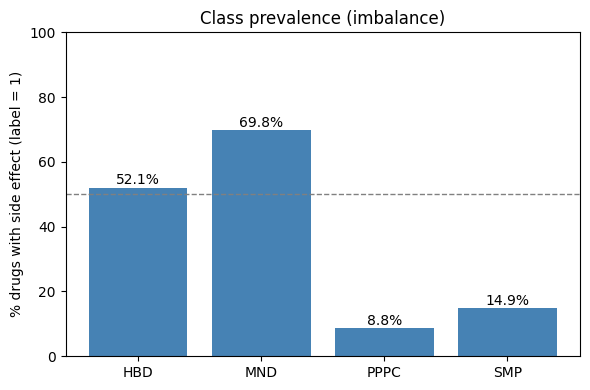

In [3]:
# Part 1 - Step 2: Select the 4 target labels and check class prevalence
labels = {
    "HBD":  "Hepatobiliary disorders",
    "MND":  "Metabolism and nutrition disorders",
    "PPPC": "Pregnancy, puerperium and perinatal conditions",
    "SMP":  "Surgical and medical procedures",
}

# Make sure every column name exists in the dataset
missing = [c for c in labels.values() if c not in df.columns]
print("Missing label columns:", missing)

# Target matrix with short names
Y = df[list(labels.values())].copy()
Y.columns = list(labels.keys())

summary = pd.DataFrame({
    "positives": Y.sum(),
    "negatives": (1 - Y).sum(),
    "prevalence_%": (Y.mean() * 100).round(1),
})
print(summary)

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(summary.index, summary["prevalence_%"], color="steelblue")
ax.axhline(50, color="gray", linestyle="--", linewidth=1)
for b, v in zip(bars, summary["prevalence_%"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylabel("% drugs with side effect (label = 1)")
ax.set_title("Class prevalence (imbalance)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig("class_prevalence.png", dpi=150)
plt.show()

## Part 2: Features (Fingerprints and Descriptors)
Convert each molecule into numbers that a machine learning model can use.

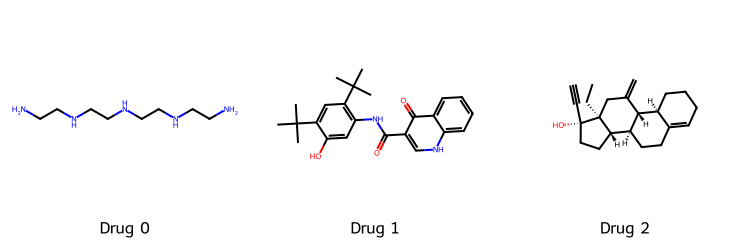

Length of fingerprint: 2048
Number of 1s (bits ON): 11
Positions of ON bits: [  80  667  897  981 1004 1152 1171 1322 1760 1840 1911]

Shape of the 3-drug fingerprint table: (3, 2048)


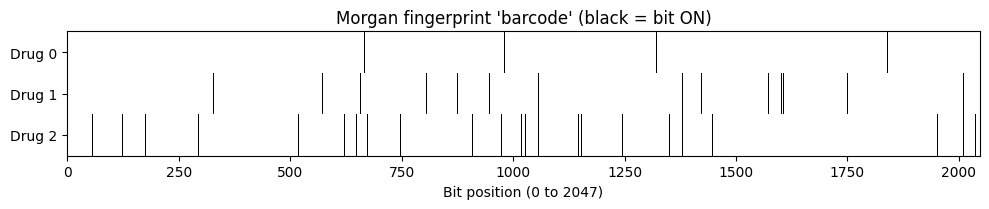

In [4]:
# Part 2 - Step 1: Understand a fingerprint using 3 example drugs
from rdkit.Chem import Draw, rdFingerprintGenerator
from IPython.display import display

# Take the first 3 molecules (already created in Part 1)
sample_mols = mols[:3]

# 1) Draw the 3 molecules
img = Draw.MolsToGridImage(
    sample_mols,
    molsPerRow=3,
    subImgSize=(250, 250),
    legends=["Drug 0", "Drug 1", "Drug 2"],
)
display(img)

# 2) Create a Morgan fingerprint generator (2048 boxes, radius 2)
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# 3) Fingerprint of Drug 0 only
fp0 = morgan_gen.GetFingerprintAsNumPy(sample_mols[0])
print("Length of fingerprint:", len(fp0))
print("Number of 1s (bits ON):", fp0.sum())
print("Positions of ON bits:", np.where(fp0 == 1)[0])

# 4) Fingerprints of all 3 drugs as a 'barcode' picture
fps = np.array([morgan_gen.GetFingerprintAsNumPy(m) for m in sample_mols])
print("\nShape of the 3-drug fingerprint table:", fps.shape)

fig, ax = plt.subplots(figsize=(10, 2.2))
ax.imshow(fps, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Drug 0", "Drug 1", "Drug 2"])
ax.set_xlabel("Bit position (0 to 2047)")
ax.set_title("Morgan fingerprint 'barcode' (black = bit ON)")
plt.tight_layout()
plt.show()

fingerprint        shape  avg_bits_ON  empty_drugs (all zeros)
     Morgan (1427, 2048)         46.5                        0
   AtomPair (1427, 2048)        309.7                       31
    Torsion (1427, 2048)         49.3                       60
    Pattern (1427, 2048)        451.3                        0


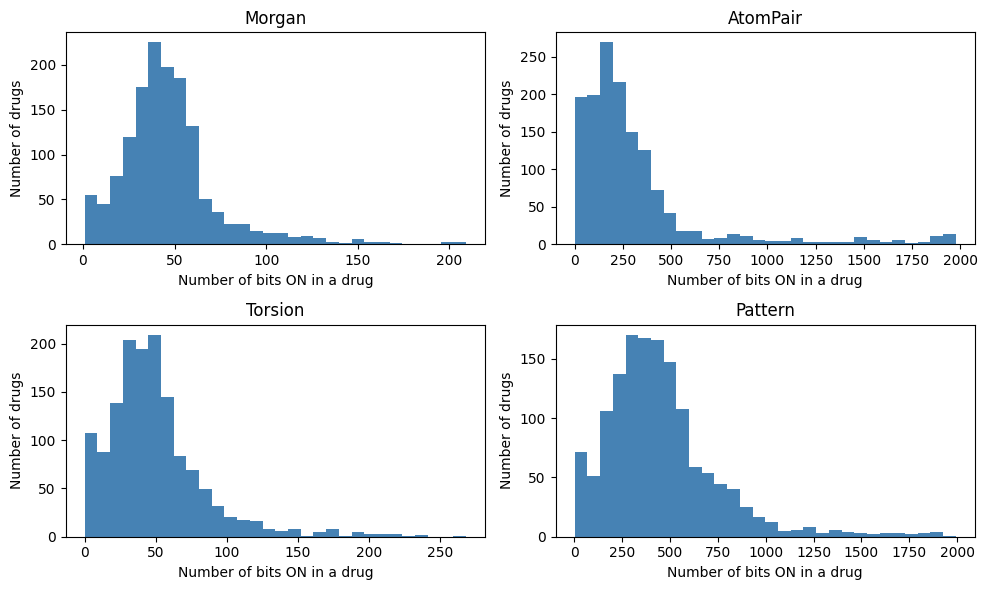

In [5]:
# Part 2 - Step 2: Build 4 fingerprints for all 1427 drugs
from rdkit import DataStructs
from rdkit import Chem

# 1) Three fingerprint "machines", each makes 2048 boxes
generators = {
    "Morgan":   rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048),
    "AtomPair": rdFingerprintGenerator.GetAtomPairGenerator(fpSize=2048),
    "Torsion":  rdFingerprintGenerator.GetTopologicalTorsionGenerator(fpSize=2048),
}

# 2) Make the fingerprint table for every drug (rows = drugs, columns = 2048 bits)
FP = {}
for name, gen in generators.items():
    FP[name] = np.array([gen.GetFingerprintAsNumPy(m) for m in mols])

# 3) Pattern fingerprint needs a small helper function
def pattern_fp(mol):
    arr = np.zeros((2048,), dtype=np.uint8)            # 2048 empty boxes
    bitvect = Chem.PatternFingerprint(mol, fpSize=2048)  # RDKit's own format
    DataStructs.ConvertToNumpyArray(bitvect, arr)       # copy it into our boxes
    return arr

FP["Pattern"] = np.array([pattern_fp(m) for m in mols])

# 4) Check: table size, empty rows, average bits ON
check = []
for name, table in FP.items():
    bits_on = table.sum(axis=1)               # bits ON for each drug
    check.append({
        "fingerprint": name,
        "shape": table.shape,
        "avg_bits_ON": round(bits_on.mean(), 1),
        "empty_drugs (all zeros)": int((bits_on == 0).sum()),
    })
print(pd.DataFrame(check).to_string(index=False))

# 5) Graph: how many bits are ON per drug, for each fingerprint
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (name, table) in zip(axes.ravel(), FP.items()):
    ax.hist(table.sum(axis=1), bins=30, color="steelblue")
    ax.set_title(name)
    ax.set_xlabel("Number of bits ON in a drug")
    ax.set_ylabel("Number of drugs")
plt.tight_layout()
plt.savefig("fingerprint_bits_on.png", dpi=150)
plt.show()

===== Raw descriptors (summary) =====
         MolWt  NumValenceElectrons
count  1427.00              1427.00
mean    492.93               182.96
std     691.27               264.66
min       6.94                 0.00
25%     258.23                94.00
50%     353.34               132.00
75%     472.98               174.00
max    7594.91              2702.00

===== Skewness: raw vs log2 =====
                   raw  log2
MolWt             6.34  0.31
ValenceElectrons  6.29 -0.97

Correlation (raw) : 0.996
Correlation (log2): 0.936


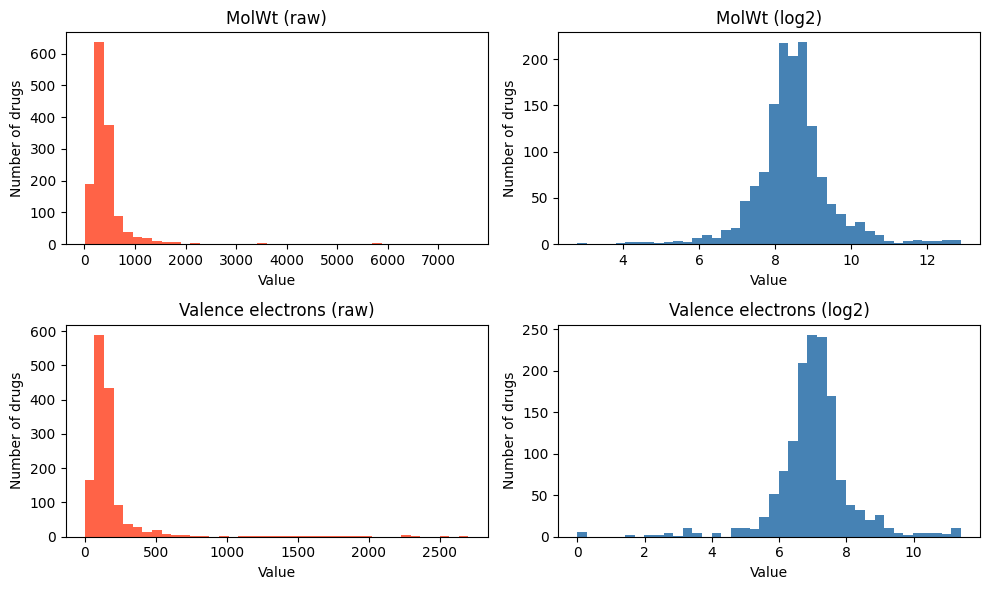

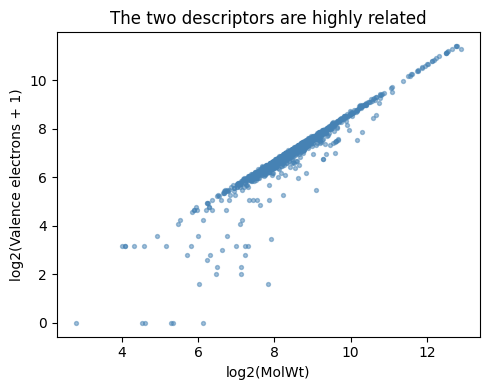

In [6]:
# Part 2 - Step 3: Two descriptors (MolWt, Valence Electrons) and the log2 fix
from rdkit.Chem import Descriptors

# 1) Raw descriptors for all 1427 drugs
desc_raw = pd.DataFrame({
    "MolWt": [Descriptors.MolWt(m) for m in mols],
    "NumValenceElectrons": [Descriptors.NumValenceElectrons(m) for m in mols],
})
print("===== Raw descriptors (summary) =====")
print(desc_raw.describe().round(2))

# 2) log2 version (+1 for valence electrons, because the minimum is 0)
desc_log = pd.DataFrame({
    "log2_MolWt":   np.log2(desc_raw["MolWt"]),
    "log2_ValElec": np.log2(desc_raw["NumValenceElectrons"] + 1),
})

# 3) Skewness before vs after (0 = symmetric, big positive = long right tail)
skew_table = pd.DataFrame({
    "raw":  desc_raw.skew().values,
    "log2": desc_log.skew().values,
}, index=["MolWt", "ValenceElectrons"]).round(2)
print("\n===== Skewness: raw vs log2 =====")
print(skew_table)

# 4) Correlation between the 2 descriptors
print("\nCorrelation (raw) :", round(desc_raw.corr().iloc[0, 1], 3))
print("Correlation (log2):", round(desc_log.corr().iloc[0, 1], 3))

# 5) Graph 1: histograms, raw vs log2
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].hist(desc_raw["MolWt"], bins=40, color="tomato")
axes[0, 0].set_title("MolWt (raw)")
axes[0, 1].hist(desc_log["log2_MolWt"], bins=40, color="steelblue")
axes[0, 1].set_title("MolWt (log2)")
axes[1, 0].hist(desc_raw["NumValenceElectrons"], bins=40, color="tomato")
axes[1, 0].set_title("Valence electrons (raw)")
axes[1, 1].hist(desc_log["log2_ValElec"], bins=40, color="steelblue")
axes[1, 1].set_title("Valence electrons (log2)")
for ax in axes.ravel():
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of drugs")
plt.tight_layout()
plt.savefig("descriptors_raw_vs_log2.png", dpi=150)
plt.show()

# 6) Graph 2: how closely the two descriptors move together
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(desc_log["log2_MolWt"], desc_log["log2_ValElec"], s=8, alpha=0.5, color="steelblue")
ax.set_xlabel("log2(MolWt)")
ax.set_ylabel("log2(Valence electrons + 1)")
ax.set_title("The two descriptors are highly related")
plt.tight_layout()
plt.savefig("descriptors_scatter.png", dpi=150)
plt.show()

## Part 3: Train / Test Split
80% of drugs for training, 20% held out for the final test. Stratified so rare labels stay balanced.

Drugs in each PPPC_SMP group:
0_0    1136
0_1     166
1_0      78
1_1      47
Name: count, dtype: int64

Train size: 1141 | Test size: 286

Prevalence in train vs test:
      Train_%  Test_%
HBD      52.3    51.0
MND      69.5    71.0
PPPC      8.8     8.7
SMP      15.0    14.7

Number of positive drugs in test:
HBD     146
MND     203
PPPC     25
SMP      42
dtype: int64


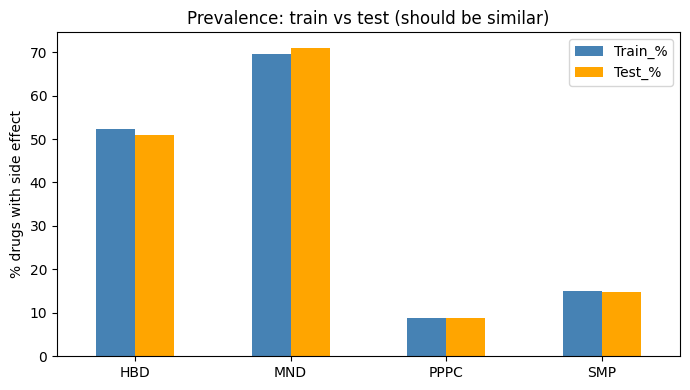

In [7]:
# Part 3 - Step 1: Stratified train / test split
from sklearn.model_selection import train_test_split

# 1) One key that combines the two rare labels, so both stay balanced
strat_key = Y["PPPC"].astype(str) + "_" + Y["SMP"].astype(str)
print("Drugs in each PPPC_SMP group:")
print(strat_key.value_counts())

# 2) Split the row numbers (0 to 1426), not the data itself
idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(
    idx, test_size=0.20, random_state=SEED, stratify=strat_key
)

# 3) Pick the label rows for train and test
Y_tr = Y.iloc[tr_idx]
Y_te = Y.iloc[te_idx]
print("\nTrain size:", len(tr_idx), "| Test size:", len(te_idx))

# 4) Compare prevalence (%) in train vs test
prev_df = pd.DataFrame({
    "Train_%": (Y_tr.mean() * 100).round(1),
    "Test_%":  (Y_te.mean() * 100).round(1),
})
print("\nPrevalence in train vs test:")
print(prev_df)
print("\nNumber of positive drugs in test:")
print(Y_te.sum())

# 5) Graph: train vs test prevalence side by side
ax = prev_df.plot(kind="bar", figsize=(7, 4), color=["steelblue", "orange"], rot=0)
ax.set_ylabel("% drugs with side effect")
ax.set_title("Prevalence: train vs test (should be similar)")
plt.tight_layout()
plt.savefig("train_test_prevalence.png", dpi=150)
plt.show()

Scaled descriptors - TRAIN: mean = [-0. -0.]  std = [1. 1.]
Scaled descriptors - TEST : mean = [-0.027  0.011]  std = [0.953 0.853]

===== Feature sets =====
              train_shape   test_shape
Morgan       (1141, 2048)  (286, 2048)
AtomPair     (1141, 2048)  (286, 2048)
Torsion      (1141, 2048)  (286, 2048)
Pattern      (1141, 2048)  (286, 2048)
Descriptors     (1141, 2)     (286, 2)
Hybrid       (1141, 2050)  (286, 2050)


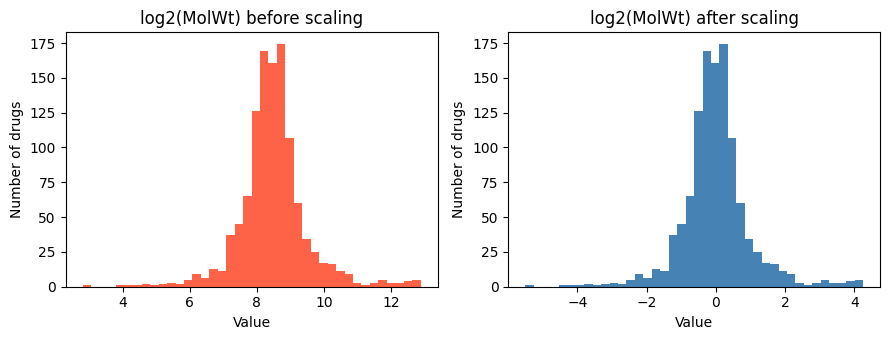

In [8]:
# Part 3 - Step 2: Build the 6 feature sets (with scaling fitted on train only)
from sklearn.preprocessing import StandardScaler

# 1) Learn mean and std from the TRAIN rows only
scaler = StandardScaler()
scaler.fit(desc_log.iloc[tr_idx])

# 2) Apply the same scaling to train and test
D_tr = scaler.transform(desc_log.iloc[tr_idx])
D_te = scaler.transform(desc_log.iloc[te_idx])

print("Scaled descriptors - TRAIN: mean =", D_tr.mean(axis=0).round(3), " std =", D_tr.std(axis=0).round(3))
print("Scaled descriptors - TEST : mean =", D_te.mean(axis=0).round(3), " std =", D_te.std(axis=0).round(3))

# 3) Hybrid = Morgan bits + 2 scaled descriptors, side by side
H_tr = np.hstack([FP["Morgan"][tr_idx], D_tr])
H_te = np.hstack([FP["Morgan"][te_idx], D_te])

# 4) Put all 6 feature sets in one dictionary: name -> (train table, test table)
FEATS = {}
for name in ["Morgan", "AtomPair", "Torsion", "Pattern"]:
    FEATS[name] = (FP[name][tr_idx], FP[name][te_idx])
FEATS["Descriptors"] = (D_tr, D_te)
FEATS["Hybrid"] = (H_tr, H_te)

# 5) Check the size of every feature set
shape_table = pd.DataFrame({
    "train_shape": [FEATS[k][0].shape for k in FEATS],
    "test_shape":  [FEATS[k][1].shape for k in FEATS],
}, index=list(FEATS.keys()))
print("\n===== Feature sets =====")
print(shape_table)

# 6) Graph: log2 MolWt in the train set, before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(desc_log["log2_MolWt"].iloc[tr_idx], bins=40, color="tomato")
axes[0].set_title("log2(MolWt) before scaling")
axes[1].hist(D_tr[:, 0], bins=40, color="steelblue")
axes[1].set_title("log2(MolWt) after scaling")
for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of drugs")
plt.tight_layout()
plt.savefig("scaling_before_after.png", dpi=150)
plt.show()

## Part 4: Baseline Models
Compare 3 models (Logistic Regression, SVM, AdaBoost) on 6 feature sets for each label.
Scores come from 5-fold cross-validation on the TRAIN set only. The test set is not used here.

Label: HBD | Prevalence in train: 0.523
Silly baseline accuracy (always bigger class): 0.523

Accuracy : 0.675
Precision: 0.689
Recall   : 0.69
F1       : 0.69
ROC-AUC  : 0.719
PR-AUC   : 0.7 (random level = 0.523 )


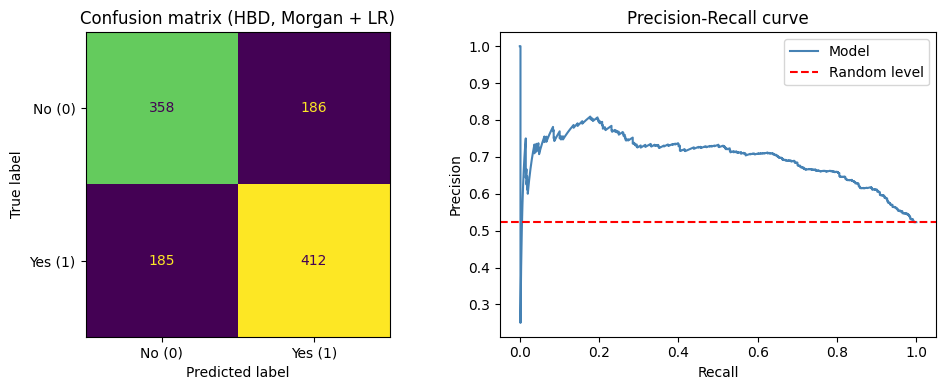

In [9]:
# Part 4 - Step 1: One label, one model - understand the metrics
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

# 1) Choose one example: label HBD, Morgan fingerprint, Logistic Regression
lab = "HBD"
Xtr = FEATS["Morgan"][0]          # train table only
ytr = Y_tr[lab].values            # train labels (0/1)

# 2) 5-fold cross-validation on the train set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
model = LogisticRegression(max_iter=2000, random_state=SEED)

# score = how strongly the model says "positive" (higher = more sure)
score = cross_val_predict(model, Xtr, ytr, cv=cv, method="decision_function")
pred = (score > 0).astype(int)    # score above 0 means predict 1

# 3) Compare with the "silly baseline" (always say the bigger class)
prev = ytr.mean()
print("Label:", lab, "| Prevalence in train:", round(prev, 3))
print("Silly baseline accuracy (always bigger class):", round(max(prev, 1 - prev), 3))

# 4) Metrics
print("\nAccuracy :", round(accuracy_score(ytr, pred), 3))
print("Precision:", round(precision_score(ytr, pred, zero_division=0), 3))
print("Recall   :", round(recall_score(ytr, pred, zero_division=0), 3))
print("F1       :", round(f1_score(ytr, pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(ytr, score), 3))
print("PR-AUC   :", round(average_precision_score(ytr, score), 3), "(random level =", round(prev, 3), ")")

# 5) Graphs: confusion matrix and precision-recall curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm = confusion_matrix(ytr, pred)
ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (HBD, Morgan + LR)")

p, r, _ = precision_recall_curve(ytr, score)
axes[1].plot(r, p, color="steelblue", label="Model")
axes[1].axhline(prev, color="red", linestyle="--", label="Random level")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("example_metrics_hbd.png", dpi=150)
plt.show()

HBD done | time so far: 127 sec
MND done | time so far: 225 sec
PPPC done | time so far: 315 sec
SMP done | time so far: 407 sec

Total combinations: 72

Silly baseline accuracy:
HBD     0.523
MND     0.695
PPPC    0.912
SMP     0.850

===== PR-AUC (CV, train) =====
label                HBD    MND   PPPC    SMP
feat        model                            
AtomPair    ADA    0.677  0.735  0.160  0.195
            LR     0.669  0.739  0.138  0.206
            SVM    0.735  0.754  0.207  0.222
Descriptors ADA    0.574  0.704  0.114  0.156
            LR     0.501  0.720  0.093  0.133
            SVM    0.584  0.708  0.092  0.183
Hybrid      ADA    0.653  0.737  0.157  0.162
            LR     0.698  0.749  0.171  0.215
            SVM    0.756  0.757  0.212  0.223
Morgan      ADA    0.657  0.745  0.160  0.162
            LR     0.700  0.747  0.172  0.216
            SVM    0.756  0.745  0.210  0.224
Pattern     ADA    0.659  0.747  0.118  0.206
            LR     0.648  0.721  0.157  0.1

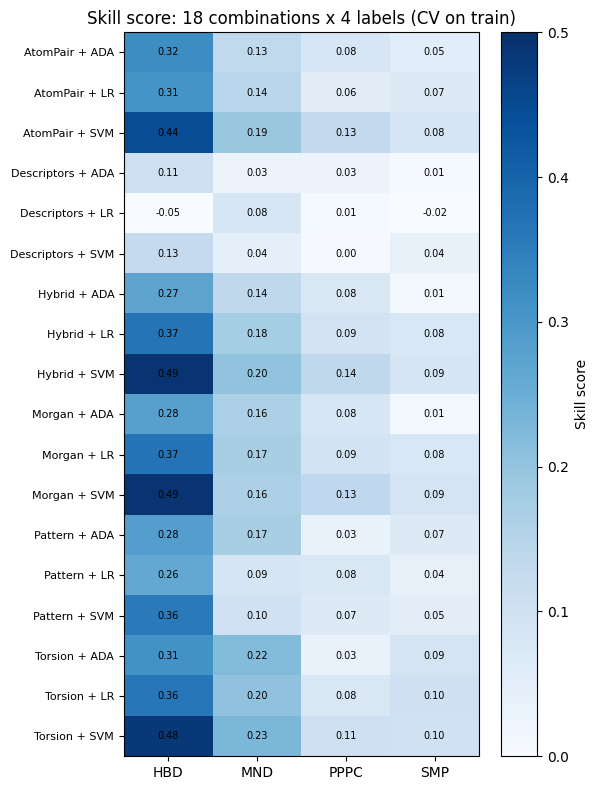

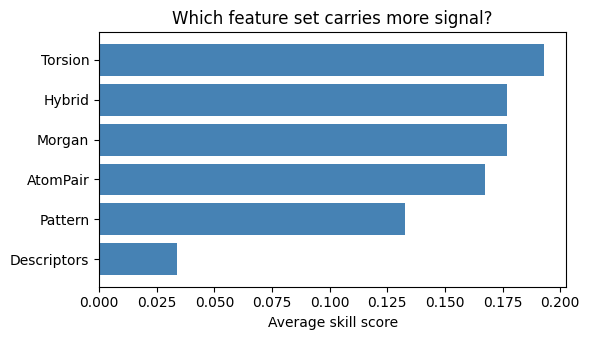

In [10]:
# Part 4 - Step 2: All 72 combinations, 5-fold cross-validation on the TRAIN set only
import time
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier

# 1) The three models, created fresh each time we call this function
def get_models():
    return {
        "LR":  LogisticRegression(max_iter=2000, random_state=SEED),
        "SVM": SVC(random_state=SEED),
        "ADA": AdaBoostClassifier(n_estimators=100, random_state=SEED),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 2) Loop: label -> feature set -> model
rows = []
cv_store = {}          # keep every score, we will need them in later steps
t0 = time.time()

for lab in labels.keys():
    ytr = Y_tr[lab].values
    prev = ytr.mean()
    for fname in FEATS:
        Xtr = FEATS[fname][0]                      # train table only
        for mname, model in get_models().items():
            score = cross_val_predict(model, Xtr, ytr, cv=cv,
                                      method="decision_function", n_jobs=-1)
            pred = (score > 0).astype(int)
            pr = average_precision_score(ytr, score)
            cv_store[(lab, fname, mname)] = score
            rows.append({
                "label": lab, "feat": fname, "model": mname,
                "ACC": accuracy_score(ytr, pred),
                "ROC": roc_auc_score(ytr, score),
                "PR": pr,
                "Skill": (pr - prev) / (1 - prev),
            })
    print(f"{lab} done | time so far: {time.time() - t0:.0f} sec")

cv_res = pd.DataFrame(rows)
cv_res.to_csv("cv_baseline_results.csv", index=False)
print("\nTotal combinations:", len(cv_res))

# 3) Silly baseline accuracy (always say the bigger class) for each label
silly = pd.Series({lab: max(Y_tr[lab].mean(), 1 - Y_tr[lab].mean()) for lab in labels})
print("\nSilly baseline accuracy:")
print(silly.round(3).to_string())

# 4) Tables: PR-AUC and Skill for every combination
order = list(labels.keys())
print("\n===== PR-AUC (CV, train) =====")
print(cv_res.pivot_table(index=["feat", "model"], columns="label", values="PR")[order].round(3))
print("\n===== Skill score (0 = random, 1 = perfect) =====")
skill_tab = cv_res.pivot_table(index=["feat", "model"], columns="label", values="Skill")[order]
print(skill_tab.round(3))

# 5) Graph 1: heatmap of the skill score
fig, ax = plt.subplots(figsize=(6, 8))
im = ax.imshow(skill_tab.values, cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_yticks(range(len(skill_tab)))
ax.set_yticklabels([f"{f} + {m}" for f, m in skill_tab.index], fontsize=8)
for i in range(skill_tab.shape[0]):
    for j in range(skill_tab.shape[1]):
        ax.text(j, i, f"{skill_tab.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Skill score")
ax.set_title("Skill score: 18 combinations x 4 labels (CV on train)")
plt.tight_layout()
plt.savefig("cv_skill_heatmap.png", dpi=150)
plt.show()

# 6) Graph 2: average skill of each feature set (over all labels and models)
avg_feat = cv_res.groupby("feat")["Skill"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(avg_feat.index, avg_feat.values, color="steelblue")
ax.set_xlabel("Average skill score")
ax.set_title("Which feature set carries more signal?")
plt.tight_layout()
plt.savefig("cv_skill_by_feature.png", dpi=150)
plt.show()

## Part 5: Class Weighting
Give rare-class drugs a larger weight during training. Before vs after is compared on the SAME model.

Positives in train: 100 | Negatives in train: 1041
Weight of a negative drug (0): 0.548
Weight of a positive drug (1): 5.705

===== PPPC | Morgan + SVM | 5-fold CV on train =====
               Before (no weights)  After (weighted)
Accuracy                     0.912             0.904
Precision                    0.000             0.404
Recall                       0.000             0.210
MCC                          0.000             0.244
PR-AUC                       0.210             0.198
Predicted Yes                0.000            52.000

Silly baseline accuracy: 0.912


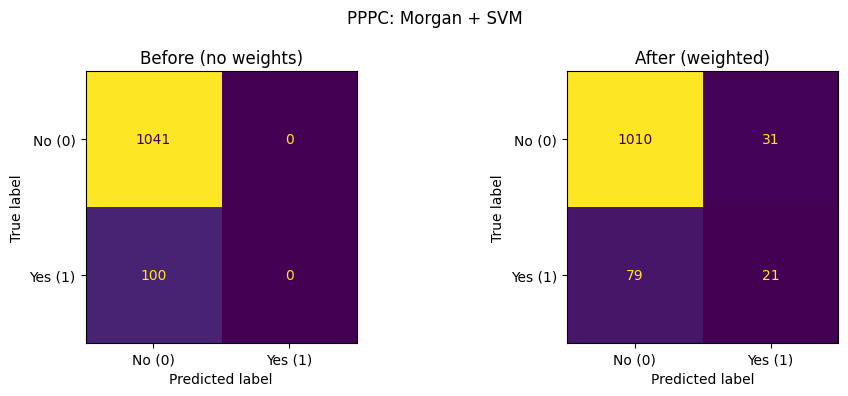

In [11]:
# Part 5 - Step 1: Class weighting on ONE example (PPPC, Morgan, SVM)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import matthews_corrcoef

lab, fname, mname = "PPPC", "Morgan", "SVM"
Xtr = FEATS[fname][0]
ytr = Y_tr[lab].values

# 1) Weight of every training drug ("balanced" = rare class gets a bigger weight)
sw = compute_sample_weight("balanced", ytr)
print("Positives in train:", int(ytr.sum()), "| Negatives in train:", int((ytr == 0).sum()))
print("Weight of a negative drug (0):", round(sw[ytr == 0][0], 3))
print("Weight of a positive drug (1):", round(sw[ytr == 1][0], 3))

# 2) BEFORE: scores already saved in Part 4 (no weights)
score_before = cv_store[(lab, fname, mname)]
pred_before = (score_before > 0).astype(int)

# 3) AFTER: same model, same 5 folds, but with sample weights
model = get_models()[mname]
score_after = cross_val_predict(model, Xtr, ytr, cv=cv,
                                method="decision_function",
                                params={"sample_weight": sw})
pred_after = (score_after > 0).astype(int)

# 4) Compare the two
def metrics_row(y, score, pred):
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall":    recall_score(y, pred, zero_division=0),
        "MCC":       matthews_corrcoef(y, pred),
        "PR-AUC":    average_precision_score(y, score),
        "Predicted Yes": int(pred.sum()),
    }

compare = pd.DataFrame({
    "Before (no weights)": metrics_row(ytr, score_before, pred_before),
    "After (weighted)":    metrics_row(ytr, score_after, pred_after),
}).round(3)
print("\n===== PPPC | Morgan + SVM | 5-fold CV on train =====")
print(compare)
print("\nSilly baseline accuracy:", round(max(ytr.mean(), 1 - ytr.mean()), 3))

# 5) Graph: confusion matrices before and after
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], pred_before, "Before (no weights)"),
                        (axes[1], pred_after,  "After (weighted)")]:
    cm = confusion_matrix(ytr, pred)
    ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.suptitle("PPPC: Morgan + SVM")
plt.tight_layout()
plt.savefig("weighting_example_pppc.png", dpi=150)
plt.show()

HBD done | time so far: 103 sec
MND done | time so far: 208 sec
PPPC done | time so far: 303 sec
SMP done | time so far: 400 sec

===== Average over 18 combinations: before vs after weighting =====
       PR_before  PR_after  Rec_before  Rec_after  MCC_before  MCC_after
label                                                                   
HBD        0.671     0.672       0.746      0.703       0.301      0.291
MND        0.740     0.747       0.926      0.658       0.038      0.127
PPPC       0.154     0.154       0.038      0.347       0.046      0.128
SMP        0.199     0.200       0.046      0.357       0.049      0.086

===== Combinations (out of 18) where the value went UP after weighting =====
       PR improved  MCC improved
label                           
HBD             12             7
MND             12            17
PPPC            10            14
SMP             11            12


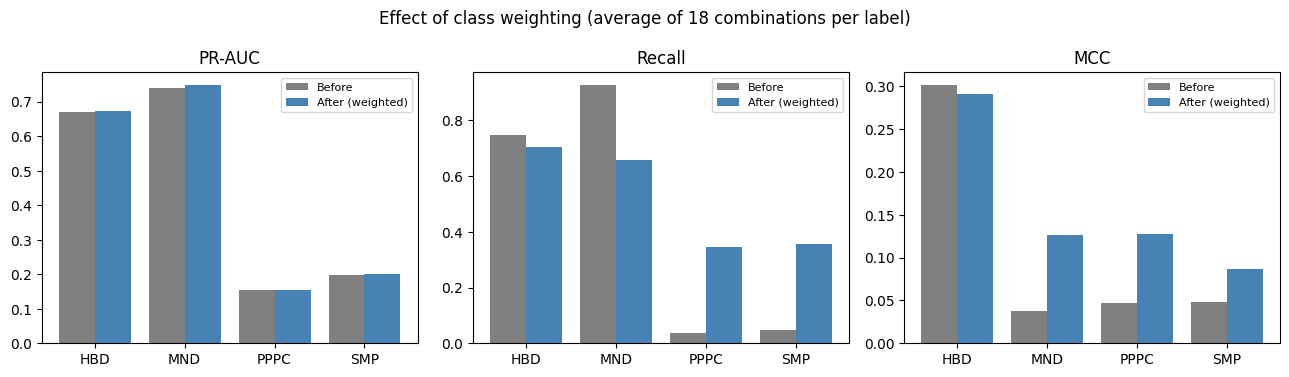

In [12]:
# Part 5 - Step 2: Weighting on ALL 72 combinations (same model, before vs after)
rows_w = []
cv_store_w = {}          # weighted scores, needed in later parts
t0 = time.time()

for lab in labels.keys():
    ytr = Y_tr[lab].values
    sw = compute_sample_weight("balanced", ytr)      # weights for this label
    for fname in FEATS:
        Xtr = FEATS[fname][0]
        for mname, model in get_models().items():
            # AFTER: same model, same 5 folds, with weights
            score_a = cross_val_predict(model, Xtr, ytr, cv=cv,
                                        method="decision_function", n_jobs=-1,
                                        params={"sample_weight": sw})
            pred_a = (score_a > 0).astype(int)
            # BEFORE: saved in Part 4
            score_b = cv_store[(lab, fname, mname)]
            pred_b = (score_b > 0).astype(int)

            cv_store_w[(lab, fname, mname)] = score_a
            rows_w.append({
                "label": lab, "feat": fname, "model": mname,
                "PR_before":  average_precision_score(ytr, score_b),
                "PR_after":   average_precision_score(ytr, score_a),
                "Rec_before": recall_score(ytr, pred_b, zero_division=0),
                "Rec_after":  recall_score(ytr, pred_a, zero_division=0),
                "MCC_before": matthews_corrcoef(ytr, pred_b),
                "MCC_after":  matthews_corrcoef(ytr, pred_a),
            })
    print(f"{lab} done | time so far: {time.time() - t0:.0f} sec")

w_res = pd.DataFrame(rows_w)
w_res.to_csv("cv_weighted_results.csv", index=False)

# 1) Average over the 18 combinations of each label
cols = ["PR_before", "PR_after", "Rec_before", "Rec_after", "MCC_before", "MCC_after"]
avg = w_res.groupby("label")[cols].mean().loc[list(labels.keys())]
print("\n===== Average over 18 combinations: before vs after weighting =====")
print(avg.round(3))

# 2) In how many of the 18 combinations did each number improve?
count = pd.DataFrame({
    "PR improved":  w_res.groupby("label").apply(lambda d: int((d["PR_after"]  > d["PR_before"]).sum())),
    "MCC improved": w_res.groupby("label").apply(lambda d: int((d["MCC_after"] > d["MCC_before"]).sum())),
}).loc[list(labels.keys())]
print("\n===== Combinations (out of 18) where the value went UP after weighting =====")
print(count)

# 3) Graph: before vs after for PR-AUC, Recall and MCC
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(avg))
for ax, metric in zip(axes, ["PR", "Rec", "MCC"]):
    ax.bar(x - 0.2, avg[f"{metric}_before"], width=0.4, color="gray", label="Before")
    ax.bar(x + 0.2, avg[f"{metric}_after"],  width=0.4, color="steelblue", label="After (weighted)")
    ax.set_xticks(x)
    ax.set_xticklabels(avg.index)
    ax.set_title({"PR": "PR-AUC", "Rec": "Recall", "MCC": "MCC"}[metric])
    ax.legend(fontsize=8)
plt.suptitle("Effect of class weighting (average of 18 combinations per label)")
plt.tight_layout()
plt.savefig("weighting_before_after.png", dpi=150)
plt.show()

## Part 6: Statistical Analysis (Descriptors vs Side Effects)
Logistic regression on all 1427 drugs to test if molecular weight / valence electrons are associated with each side effect.
Note: this is inference, not prediction, so no train/test split is used here.

Odds Ratio per doubling: 1.162
95% CI                 : [ 1.061 , 1.273 ]
p-value (this variable): 0.0012
p-value (whole model vs no-variable model, LRT): 0.001


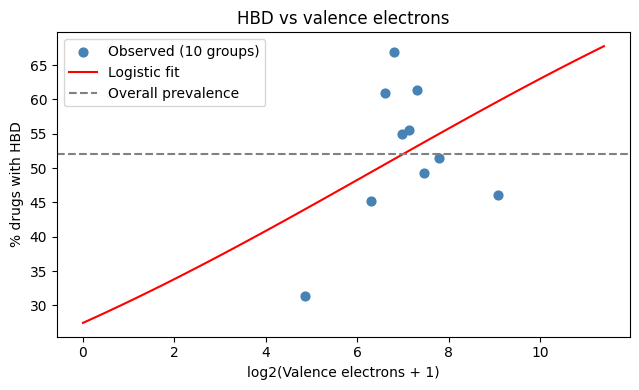

In [13]:
# Part 6 - Step 1: Logistic regression on ONE example (HBD ~ log2 valence electrons)
import statsmodels.api as sm

# 1) Data: one descriptor (X) and one label (y), all 1427 drugs
X = sm.add_constant(desc_log[["log2_ValElec"]])    # adds the intercept column
y = Y["HBD"]

# 2) Fit the model
model = sm.Logit(y, X).fit(disp=0)

# 3) Odds Ratio per doubling, with 95% confidence interval and p-values
odds_ratio = np.exp(model.params["log2_ValElec"])
ci = np.exp(model.conf_int().loc["log2_ValElec"])
print("Odds Ratio per doubling:", round(odds_ratio, 3))
print("95% CI                 : [", round(ci[0], 3), ",", round(ci[1], 3), "]")
print("p-value (this variable):", round(model.pvalues["log2_ValElec"], 4))
print("p-value (whole model vs no-variable model, LRT):", round(model.llr_pvalue, 4))

# 4) Graph: observed % of drugs with HBD in 10 equal-sized groups + fitted curve
groups = pd.qcut(desc_log["log2_ValElec"], 10, duplicates="drop")
obs_prev = y.groupby(groups, observed=True).mean() * 100
obs_x = desc_log["log2_ValElec"].groupby(groups, observed=True).mean()

xs = np.linspace(desc_log["log2_ValElec"].min(), desc_log["log2_ValElec"].max(), 100)
curve = model.predict(sm.add_constant(pd.DataFrame({"log2_ValElec": xs}))) * 100

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(obs_x, obs_prev, color="steelblue", s=40, label="Observed (10 groups)")
ax.plot(xs, curve, color="red", label="Logistic fit")
ax.axhline(y.mean() * 100, color="gray", linestyle="--", label="Overall prevalence")
ax.set_xlabel("log2(Valence electrons + 1)")
ax.set_ylabel("% drugs with HBD")
ax.set_title("HBD vs valence electrons")
ax.legend()
plt.tight_layout()
plt.savefig("logit_example_hbd.png", dpi=150)
plt.show()

Correlation (log2 scale): 0.936
VIF: {'log2_MolWt': 8.1, 'log2_ValElec': 8.1} (above 5 = careful, above 10 = serious)

===== Odds ratios (per doubling) =====
label        model         term  OR_per_doubling  CI_low  CI_high  p_term  LRT_p
  HBD         both   log2_MolWt            0.528   0.358    0.780  0.0013 0.0000
  HBD         both log2_ValElec            2.012   1.397    2.898  0.0002 0.0000
  HBD   MolWt only   log2_MolWt            1.107   0.999    1.226  0.0519 0.0507
  HBD ValElec only log2_ValElec            1.162   1.061    1.273  0.0012 0.0010
  MND         both   log2_MolWt            0.859   0.635    1.162  0.3240 0.0155
  MND         both log2_ValElec            1.284   0.994    1.659  0.0552 0.0155
  MND   MolWt only   log2_MolWt            1.130   1.010    1.265  0.0323 0.0311
  MND ValElec only log2_ValElec            1.140   1.037    1.253  0.0069 0.0067
 PPPC         both   log2_MolWt            0.591   0.245    1.423  0.2406 0.1321
 PPPC         both log2_ValElec 

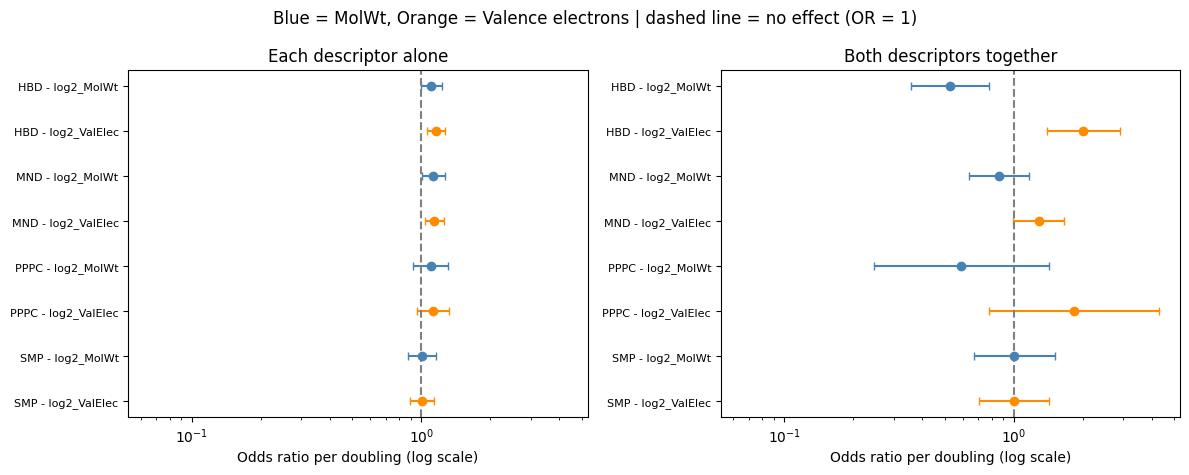

In [14]:
# Part 6 - Step 2: 4 labels x 3 models, collinearity check, Bonferroni for 12 tests
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1) Collinearity check: VIF of the two descriptors
Xc = sm.add_constant(desc_log)
vif = {col: round(float(variance_inflation_factor(Xc.values, i)), 1)
       for i, col in enumerate(Xc.columns) if col != "const"}
print("Correlation (log2 scale):", round(desc_log.corr().iloc[0, 1], 3))
print("VIF:", vif, "(above 5 = careful, above 10 = serious)")

# 2) A small function that fits one logit model and returns the results
def fit_logit(y, cols, label, tag):
    X = sm.add_constant(desc_log[cols])
    m = sm.Logit(y, X).fit(disp=0)
    ci = np.exp(m.conf_int())
    out = []
    for c in cols:
        out.append({
            "label": label, "model": tag, "term": c,
            "OR_per_doubling": np.exp(m.params[c]),
            "CI_low": ci.loc[c, 0], "CI_high": ci.loc[c, 1],
            "p_term": m.pvalues[c],
            "LRT_p": m.llr_pvalue,
        })
    return out

# 3) Fit 3 models for every label
all_rows = []
for lab in labels.keys():
    y = Y[lab]
    all_rows += fit_logit(y, ["log2_MolWt", "log2_ValElec"], lab, "both")
    all_rows += fit_logit(y, ["log2_MolWt"], lab, "MolWt only")
    all_rows += fit_logit(y, ["log2_ValElec"], lab, "ValElec only")

logit_df = pd.DataFrame(all_rows)
logit_df.to_csv("logit_odds_ratios.csv", index=False)

show = logit_df.copy()
for c in ["OR_per_doubling", "CI_low", "CI_high"]:
    show[c] = show[c].round(3)
show["p_term"] = show["p_term"].round(4)
show["LRT_p"] = show["LRT_p"].round(4)
print("\n===== Odds ratios (per doubling) =====")
print(show.to_string(index=False))

# 4) Bonferroni for the 12 model-level tests (LRT)
tests = logit_df.drop_duplicates(["label", "model"])[["label", "model", "LRT_p"]].reset_index(drop=True)
n_tests = len(tests)
threshold = 0.05 / n_tests
tests["adjusted_p"] = (tests["LRT_p"] * n_tests).clip(upper=1)
tests["significant"] = tests["LRT_p"] < threshold
tests["LRT_p"] = tests["LRT_p"].round(5)
tests["adjusted_p"] = tests["adjusted_p"].round(4)
print("\nNumber of tests:", n_tests, "| Bonferroni threshold:", round(threshold, 4))
print(tests.to_string(index=False))

# 5) Graph: odds ratios with 95% CI (blue = MolWt, orange = ValElec)
single = logit_df[logit_df["model"] != "both"].reset_index(drop=True)
both = logit_df[logit_df["model"] == "both"].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, data, title in [(axes[0], single, "Each descriptor alone"),
                        (axes[1], both, "Both descriptors together")]:
    ypos = np.arange(len(data))[::-1]
    for y_, (_, r) in zip(ypos, data.iterrows()):
        color = "steelblue" if r["term"] == "log2_MolWt" else "darkorange"
        ax.errorbar(r["OR_per_doubling"], y_,
                    xerr=[[r["OR_per_doubling"] - r["CI_low"]],
                          [r["CI_high"] - r["OR_per_doubling"]]],
                    fmt="o", color=color, capsize=3)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_yticks(ypos)
    ax.set_yticklabels([f'{r["label"]} - {r["term"]}' for _, r in data.iterrows()], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Odds ratio per doubling (log scale)")
    ax.set_title(title)
plt.suptitle("Blue = MolWt, Orange = Valence electrons | dashed line = no effect (OR = 1)")
plt.tight_layout()
plt.savefig("logit_forest_plot.png", dpi=150)
plt.show()

### Part 6 conclusion
- MolWt and valence electrons are highly correlated (r = 0.936, VIF = 8.1), so coefficients in the joint model should not be interpreted individually (sign flip seen for HBD).
- After Bonferroni correction for 12 tests (threshold 0.0042), only HBD shows a significant association (valence electrons alone, and both descriptors jointly).
- The effect is small (OR about 1.16 per doubling of valence electrons) and not clearly linear across the range; this is association, not prediction.
- MND is suggestive only (adjusted p = 0.080). PPPC and SMP show no association.

## Part 7: Model Selection (train cross-validation only)
Rank feature set + model combinations using 5-fold CV on the TRAIN set. The test set is not used for choosing.

===== Top 5 per label (CV on train) =====
label  rank     feat model    PR         95% CI  Skill
  HBD     1   Hybrid   SVM 0.756 [0.716, 0.795]  0.489
  HBD     2   Morgan   SVM 0.756 [0.716, 0.795]  0.489
  HBD     3  Torsion   SVM 0.753 [0.711, 0.789]  0.483
  HBD     4 AtomPair   SVM 0.735 [0.695, 0.771]  0.443
  HBD     5   Morgan    LR 0.700 [0.658, 0.745]  0.370
  MND     1  Torsion   SVM 0.765 [0.727, 0.799]  0.229
  MND     2  Torsion   ADA 0.762 [0.724, 0.793]  0.219
  MND     3  Torsion    LR 0.757 [0.719, 0.791]  0.204
  MND     4   Hybrid   SVM 0.757 [0.721, 0.792]  0.203
  MND     5 AtomPair   SVM 0.754 [0.719, 0.788]  0.193
 PPPC     1   Hybrid   SVM 0.212 [0.149, 0.308]  0.136
 PPPC     2   Morgan   SVM 0.210 [0.148, 0.307]  0.134
 PPPC     3 AtomPair   SVM 0.207 [0.138, 0.297]  0.131
 PPPC     4  Torsion   SVM 0.184 [0.130, 0.278]  0.105
 PPPC     5   Morgan    LR 0.172 [0.120, 0.255]  0.092
  SMP     1  Torsion    LR 0.237 [0.195, 0.293]  0.102
  SMP     2  Torsion   

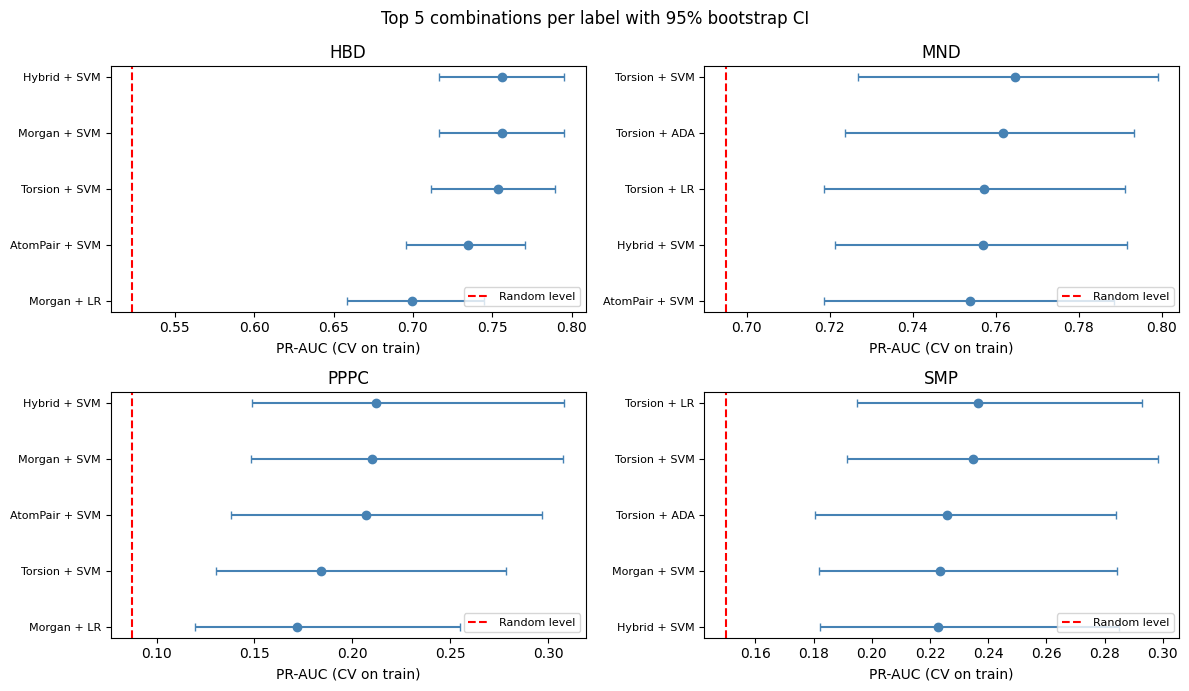

In [15]:
# Part 7 - Step 1: Top 5 combinations per label, with bootstrap 95% CI (train CV only)

# 1) Bootstrap function: resample drugs, recompute PR-AUC, take the 2.5% and 97.5% points
def boot_pr_ci(y, s, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)       # its own random generator -> same result every run
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))  # pick drugs with replacement
        if y[i].sum() == 0:                  # skip if no positive drug was picked
            continue
        vals.append(average_precision_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

# 2) For each label: take the top 5 by CV PR-AUC
top_rows = []
for lab in labels.keys():
    ytr = Y_tr[lab].values
    top5 = cv_res[cv_res["label"] == lab].sort_values("PR", ascending=False).head(5)
    for rank, (_, r) in enumerate(top5.iterrows(), start=1):
        s = cv_store[(lab, r["feat"], r["model"])]
        lo, hi = boot_pr_ci(ytr, s)
        top_rows.append({
            "label": lab, "rank": rank, "feat": r["feat"], "model": r["model"],
            "PR": r["PR"], "CI_low": lo, "CI_high": hi, "Skill": r["Skill"],
        })
top_df = pd.DataFrame(top_rows)
top_df.to_csv("cv_top5_per_label.csv", index=False)

show = top_df.copy()
show["PR"] = show["PR"].round(3)
show["Skill"] = show["Skill"].round(3)
show["95% CI"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(top_df["CI_low"], top_df["CI_high"])]
print("===== Top 5 per label (CV on train) =====")
print(show[["label", "rank", "feat", "model", "PR", "95% CI", "Skill"]].to_string(index=False))

# 3) Graph: PR-AUC with 95% CI for the top 5, one panel per label
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, lab in zip(axes.ravel(), labels.keys()):
    d = top_df[top_df["label"] == lab].reset_index(drop=True)
    ypos = np.arange(len(d))[::-1]
    ax.errorbar(d["PR"], ypos,
                xerr=[d["PR"] - d["CI_low"], d["CI_high"] - d["PR"]],
                fmt="o", color="steelblue", capsize=3)
    ax.axvline(Y_tr[lab].mean(), color="red", linestyle="--", label="Random level")
    ax.set_yticks(ypos)
    ax.set_yticklabels([f"{a} + {b}" for a, b in zip(d["feat"], d["model"])], fontsize=8)
    ax.set_xlabel("PR-AUC (CV on train)")
    ax.set_title(lab)
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Top 5 combinations per label with 95% bootstrap CI")
plt.tight_layout()
plt.savefig("cv_top5_per_label.png", dpi=150)
plt.show()

Number of candidate combinations: 12
HBD | Hybrid + SVM done | time so far: 36 sec
HBD | Morgan + SVM done | time so far: 70 sec
HBD | Torsion + SVM done | time so far: 105 sec
MND | Torsion + SVM done | time so far: 139 sec
MND | Torsion + ADA done | time so far: 189 sec
MND | Torsion + LR done | time so far: 194 sec
PPPC | Hybrid + SVM done | time so far: 221 sec
PPPC | Morgan + SVM done | time so far: 250 sec
PPPC | AtomPair + SVM done | time so far: 276 sec
SMP | Torsion + LR done | time so far: 279 sec
SMP | Torsion + SVM done | time so far: 308 sec
SMP | Torsion + ADA done | time so far: 359 sec

===== Repeated CV (5 repeats): top 3 per label =====
label  rank     feat model PR (mean ± SD)          range  gap_to_best  within_1SD_of_best
  HBD     1  Torsion   SVM  0.752 ± 0.010 [0.740, 0.760]        0.000                True
  HBD     2   Morgan   SVM  0.747 ± 0.006 [0.741, 0.755]        0.005                True
  HBD     3   Hybrid   SVM  0.746 ± 0.006 [0.741, 0.753]        0.0

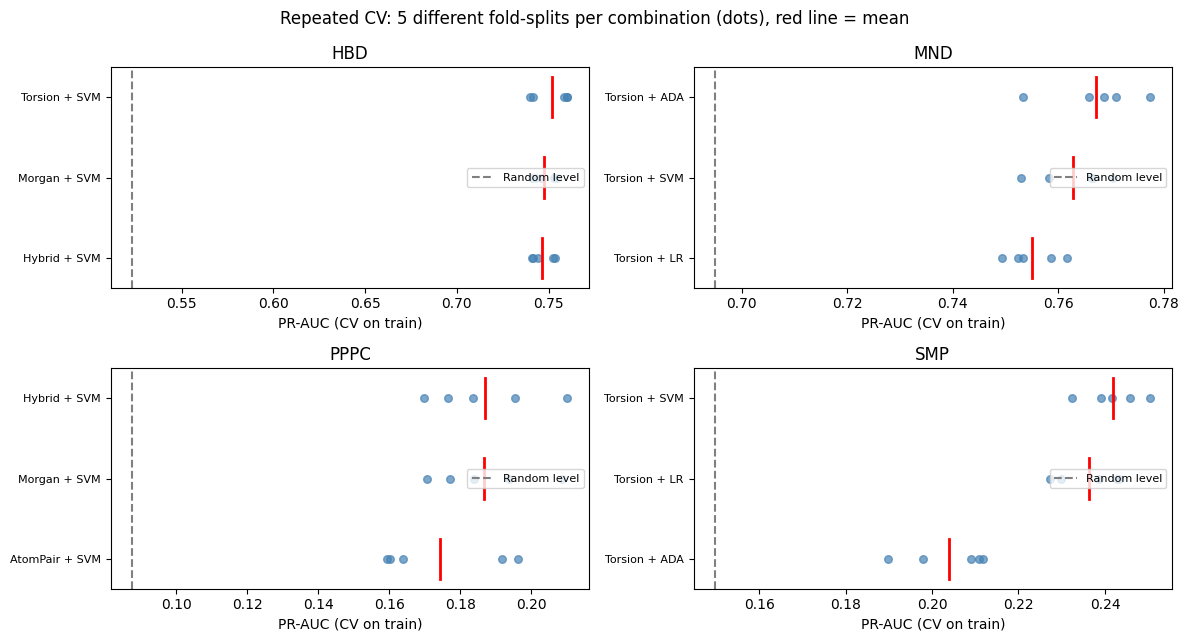

In [16]:
# Part 7 - Step 2: Repeated CV (5 different fold-splits) on the top 3 per label, TRAIN set only
N_REPEATS = 5

# 1) Candidates: the top 3 combinations of every label (from Step 1)
cand = top_df[top_df["rank"] <= 3][["label", "feat", "model"]]
print("Number of candidate combinations:", len(cand))

# 2) For every candidate, repeat the 5-fold CV with 5 different seeds
rows = []
t0 = time.time()
for _, r in cand.iterrows():
    lab, fname, mname = r["label"], r["feat"], r["model"]
    ytr = Y_tr[lab].values
    Xtr = FEATS[fname][0]
    for rep in range(N_REPEATS):
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + rep)
        score = cross_val_predict(get_models()[mname], Xtr, ytr, cv=cv_r,
                                  method="decision_function", n_jobs=-1)
        rows.append({"label": lab, "feat": fname, "model": mname,
                     "rep": rep, "PR": average_precision_score(ytr, score)})
    print(f"{lab} | {fname} + {mname} done | time so far: {time.time() - t0:.0f} sec")

rep_df = pd.DataFrame(rows)
rep_df.to_csv("repeated_cv_top3.csv", index=False)

# 3) Mean, SD, min, max over the 5 repeats
summ = (rep_df.groupby(["label", "feat", "model"])["PR"]
              .agg(["mean", "std", "min", "max"]).reset_index())
summ["label_order"] = summ["label"].map({k: i for i, k in enumerate(labels.keys())})
summ["rank"] = summ.groupby("label")["mean"].rank(ascending=False, method="first").astype(int)
summ = summ.sort_values(["label_order", "rank"]).reset_index(drop=True)

# 4) Is a combination within 1 SD of the best one of its label?
best = summ[summ["rank"] == 1].set_index("label")
summ["gap_to_best"] = [best.loc[l, "mean"] - m for l, m in zip(summ["label"], summ["mean"])]
summ["within_1SD_of_best"] = [g <= best.loc[l, "std"] for l, g in zip(summ["label"], summ["gap_to_best"])]

show = summ.copy()
show["PR (mean ± SD)"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(show["mean"], show["std"])]
show["range"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(show["min"], show["max"])]
show["gap_to_best"] = show["gap_to_best"].round(3)
print("\n===== Repeated CV (5 repeats): top 3 per label =====")
print(show[["label", "rank", "feat", "model", "PR (mean ± SD)", "range",
            "gap_to_best", "within_1SD_of_best"]].to_string(index=False))

summ.drop(columns="label_order").to_csv("repeated_cv_summary.csv", index=False)

# 5) Graph: the 5 PR-AUC values of every candidate (dots) and their mean (red line)
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, lab in zip(axes.ravel(), labels.keys()):
    d = summ[summ["label"] == lab].reset_index(drop=True)
    ypos = np.arange(len(d))[::-1]
    for y_, (_, r) in zip(ypos, d.iterrows()):
        vals = rep_df[(rep_df["label"] == lab) & (rep_df["feat"] == r["feat"]) &
                      (rep_df["model"] == r["model"])]["PR"]
        ax.scatter(vals, [y_] * len(vals), color="steelblue", s=30, alpha=0.7, zorder=3)
        ax.plot([r["mean"], r["mean"]], [y_ - 0.25, y_ + 0.25], color="red", linewidth=2, zorder=4)
    ax.axvline(Y_tr[lab].mean(), color="gray", linestyle="--", label="Random level")
    ax.set_yticks(ypos)
    ax.set_yticklabels([f"{a} + {b}" for a, b in zip(d["feat"], d["model"])], fontsize=8)
    ax.set_xlabel("PR-AUC (CV on train)")
    ax.set_title(lab)
    ax.legend(fontsize=8, loc="center right")
plt.suptitle("Repeated CV: 5 different fold-splits per combination (dots), red line = mean")
plt.tight_layout()
plt.savefig("repeated_cv_top3.png", dpi=150)
plt.show()

===== Final choice per label =====
HBD: Torsion + SVM
MND: Torsion + ADA
PPPC: Hybrid + SVM
SMP: Torsion + SVM

===== Paired PR-AUC difference (CV scores on train) =====
label  A (rank 1)  B (rank 2)  diff A-B  CI_low  CI_high             verdict   B (rank 3)
  HBD Torsion+SVM  Morgan+SVM    -0.003  -0.028    0.022 no clear difference          NaN
  HBD Torsion+SVM         NaN    -0.003  -0.027    0.022 no clear difference   Hybrid+SVM
  MND Torsion+ADA Torsion+SVM    -0.004  -0.036    0.025 no clear difference          NaN
  MND Torsion+ADA         NaN     0.004  -0.022    0.031 no clear difference   Torsion+LR
 PPPC  Hybrid+SVM  Morgan+SVM     0.002  -0.001    0.006 no clear difference          NaN
 PPPC  Hybrid+SVM         NaN     0.009  -0.027    0.050 no clear difference AtomPair+SVM
  SMP Torsion+SVM  Torsion+LR     0.000  -0.033    0.035 no clear difference          NaN
  SMP Torsion+SVM         NaN     0.011  -0.025    0.049 no clear difference  Torsion+ADA

Note: 8 comparisons

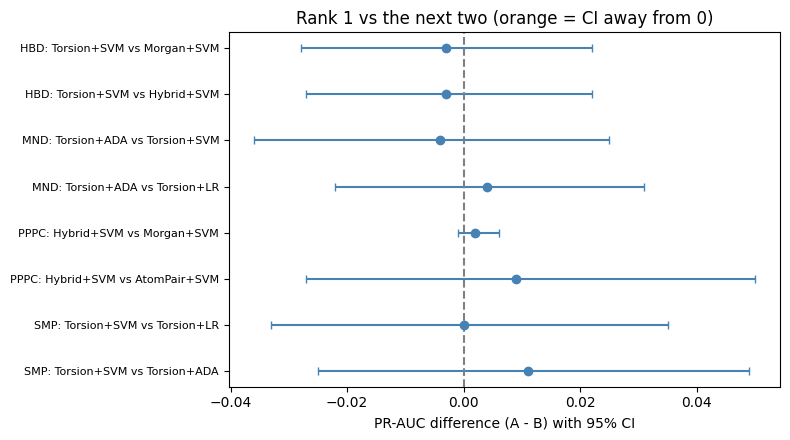

In [17]:
# Part 7 - Step 3: Final choice per label and paired comparison (train CV only)

# 1) Final choice = rank 1 in repeated CV (rule fixed in advance)
final_choice = {}
for lab in labels.keys():
    r = summ[(summ["label"] == lab) & (summ["rank"] == 1)].iloc[0]
    final_choice[lab] = (r["feat"], r["model"])
print("===== Final choice per label =====")
for lab, (f, m) in final_choice.items():
    print(f"{lab}: {f} + {m}")

# 2) Paired bootstrap: same drugs for both combinations in every round
def paired_diff_ci(y, s1, s2, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))      # one common draw of drugs
        if y[i].sum() == 0:
            continue
        d.append(average_precision_score(y[i], s1[i]) - average_precision_score(y[i], s2[i]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])

# 3) Compare rank 1 with rank 2 and rank 3, for every label
rows = []
for lab in labels.keys():
    ytr = Y_tr[lab].values
    d = summ[summ["label"] == lab].sort_values("rank")
    f1, m1 = d.iloc[0]["feat"], d.iloc[0]["model"]
    s1 = cv_store[(lab, f1, m1)]
    for k in [1, 2]:
        f2, m2 = d.iloc[k]["feat"], d.iloc[k]["model"]
        s2 = cv_store[(lab, f2, m2)]
        diff, (lo, hi) = paired_diff_ci(ytr, s1, s2)
        rows.append({
            "label": lab,
            "A (rank 1)": f"{f1}+{m1}",
            "B (rank %d)" % (k + 1): f"{f2}+{m2}",
            "diff A-B": round(diff, 3),
            "CI_low": round(lo, 3),
            "CI_high": round(hi, 3),
            "verdict": "suggestive difference" if (lo > 0 or hi < 0) else "no clear difference",
        })

pair_df = pd.DataFrame(rows)
pair_df.to_csv("paired_comparison_train_cv.csv", index=False)
print("\n===== Paired PR-AUC difference (CV scores on train) =====")
print(pair_df.to_string(index=False))
print("\nNote: 8 comparisons, no multiple-testing correction -> treat as 'suggestive' only.")

# 4) Graph: difference with 95% CI, 0 = no difference
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(pair_df))[::-1]
for y_, (_, r) in zip(ypos, pair_df.iterrows()):
    color = "darkorange" if r["verdict"] == "suggestive difference" else "steelblue"
    ax.errorbar(r["diff A-B"], y_,
                xerr=[[r["diff A-B"] - r["CI_low"]], [r["CI_high"] - r["diff A-B"]]],
                fmt="o", color=color, capsize=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(ypos)
labels_y = []
for _, r in pair_df.iterrows():
    other = r["B (rank 2)"] if pd.notna(r["B (rank 2)"]) else r["B (rank 3)"]
    labels_y.append(f'{r["label"]}: {r["A (rank 1)"]} vs {other}')
ax.set_yticklabels(labels_y, fontsize=8)
ax.set_xlabel("PR-AUC difference (A - B) with 95% CI")
ax.set_title("Rank 1 vs the next two (orange = CI away from 0)")
plt.tight_layout()
plt.savefig("paired_comparison_train_cv.png", dpi=150)
plt.show()

### Part 7 conclusion
- Models were ranked using 5-fold CV on the train set only (the test set was not used for choosing). The ranking from a single CV split was unstable, so the top 3 per label were re-ranked with 5 repeated CV splits.
- Final choice (pre-set rule: highest mean PR-AUC in repeated CV): HBD Torsion + SVM, MND Torsion + AdaBoost, PPPC Hybrid + SVM, SMP Torsion + SVM.
- Paired bootstrap comparisons (8, uncorrected, treat as suggestive only) found no clear difference between rank 1 and ranks 2-3. The choice of model is therefore not statistically supported; the top combinations are practically equivalent.
- Repeated-CV SD is smaller than the bootstrap CI because the same 1141 drugs are reused; it measures sensitivity to fold assignment, not sampling uncertainty.

HBD Torsion+SVM done | time so far: 119 sec
MND Torsion+ADA done | time so far: 272 sec
PPPC Hybrid+SVM done | time so far: 340 sec
SMP Torsion+SVM done | time so far: 419 sec

===== Tuning result (PR-AUC, CV on train) =====
label      choice  default_mean  default_SD  tuned_CV   gain  adopt_tuned                                     best_params
  HBD Torsion+SVM         0.752       0.010     0.757  0.005        False {'C': 0.3149, 'gamma': 0.0711, 'kernel': 'rbf'}
  MND Torsion+ADA         0.767       0.009     0.765 -0.002        False  {'learning_rate': 0.7406, 'n_estimators': 160}
 PPPC  Hybrid+SVM         0.187       0.016     0.232  0.045         True {'C': 4.5646, 'gamma': 0.0387, 'kernel': 'rbf'}
  SMP Torsion+SVM         0.242       0.007     0.261  0.020         True  {'C': 2.717, 'gamma': 0.0276, 'kernel': 'rbf'}

Rule: adopt tuned dials only if gain > default SD. tuned_CV is slightly optimistic.


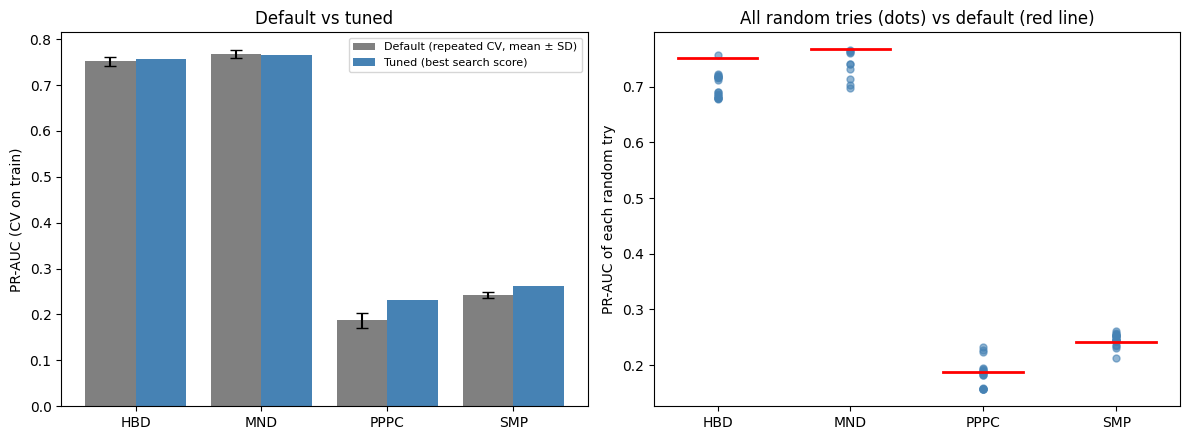

In [18]:
# Part 8 - Step 1: Hyperparameter tuning of the 4 final models (TRAIN set only)
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

pd.set_option("display.max_colwidth", 100)

# 1) Search space for each model type (model, dials to try, number of random tries)
spaces = {
    "SVM": (SVC(random_state=SEED),
            {"kernel": ["rbf", "linear"],
             "C": loguniform(1e-2, 1e2),
             "gamma": loguniform(1e-4, 1e-1)},
            20),
    "ADA": (AdaBoostClassifier(random_state=SEED),
            {"n_estimators": randint(50, 300),
             "learning_rate": loguniform(0.01, 1.5)},
            10),
}

# 2) Tune every final choice
rows = []
tuned_info = {}        # keep the decision and the dials for later parts
search_scores = {}     # keep all search scores for the graph
t0 = time.time()

for i, (lab, (fname, mname)) in enumerate(final_choice.items()):
    ytr = Y_tr[lab].values
    Xtr = FEATS[fname][0]
    est, space, n_iter = spaces[mname]

    rs = RandomizedSearchCV(est, space, n_iter=n_iter, scoring="average_precision",
                            cv=cv, random_state=SEED + i, n_jobs=-1)
    rs.fit(Xtr, ytr)                              # TRAIN set only

    # default model result from Part 7 (repeated CV)
    d = summ[(summ["label"] == lab) & (summ["feat"] == fname) &
             (summ["model"] == mname)].iloc[0]
    gain = rs.best_score_ - d["mean"]
    adopt = bool(gain > d["std"])                 # pre-set rule

    tuned_info[lab] = {"feat": fname, "model": mname,
                       "adopt": adopt, "params": rs.best_params_}
    search_scores[lab] = rs.cv_results_["mean_test_score"]

    rows.append({
        "label": lab, "choice": f"{fname}+{mname}",
        "default_mean": round(d["mean"], 3), "default_SD": round(d["std"], 3),
        "tuned_CV": round(rs.best_score_, 3), "gain": round(gain, 3),
        "adopt_tuned": adopt,
        "best_params": {k: (round(v, 4) if isinstance(v, float) else v)
                        for k, v in rs.best_params_.items()},
    })
    print(f"{lab} {fname}+{mname} done | time so far: {time.time() - t0:.0f} sec")

tune_df = pd.DataFrame(rows)
tune_df.to_csv("tuning_train_cv.csv", index=False)
print("\n===== Tuning result (PR-AUC, CV on train) =====")
print(tune_df.to_string(index=False))
print("\nRule: adopt tuned dials only if gain > default SD. tuned_CV is slightly optimistic.")

# 3) Graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# left: default (mean +/- SD) vs tuned
x = np.arange(len(tune_df))
axes[0].bar(x - 0.2, tune_df["default_mean"], width=0.4, yerr=tune_df["default_SD"],
            capsize=4, color="gray", label="Default (repeated CV, mean ± SD)")
axes[0].bar(x + 0.2, tune_df["tuned_CV"], width=0.4, color="steelblue",
            label="Tuned (best search score)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(tune_df["label"])
axes[0].set_ylabel("PR-AUC (CV on train)")
axes[0].set_title("Default vs tuned")
axes[0].legend(fontsize=8)

# right: every random try of the search (dots) vs the default (red line)
for j, lab in enumerate(tune_df["label"]):
    sc = search_scores[lab]
    axes[1].scatter([j] * len(sc), sc, color="steelblue", alpha=0.6, s=25)
    axes[1].plot([j - 0.3, j + 0.3], [tune_df.loc[j, "default_mean"]] * 2, color="red", linewidth=2)
axes[1].set_xticks(range(len(tune_df)))
axes[1].set_xticklabels(tune_df["label"])
axes[1].set_ylabel("PR-AUC of each random try")
axes[1].set_title("All random tries (dots) vs default (red line)")

plt.tight_layout()
plt.savefig("tuning_train_cv.png", dpi=150)
plt.show()

Labels to confirm: ['PPPC', 'SMP']

===== Confirmation check (new fold-splits) =====
label default (mean ± SD) tuned (mean ± SD) tuned better in  confirmed
 PPPC       0.187 ± 0.016     0.192 ± 0.015  5 of 5 repeats       True
  SMP       0.242 ± 0.007     0.239 ± 0.004  2 of 5 repeats      False

===== Final specification of the 4 models =====
HBD: Torsion + SVM | default | dials = sklearn defaults
MND: Torsion + ADA | default | dials = sklearn defaults
PPPC: Hybrid + SVM | tuned | dials = {'C': np.float64(4.564617501162753), 'gamma': np.float64(0.038727816165214826), 'kernel': 'rbf'}
SMP: Torsion + SVM | default | dials = sklearn defaults


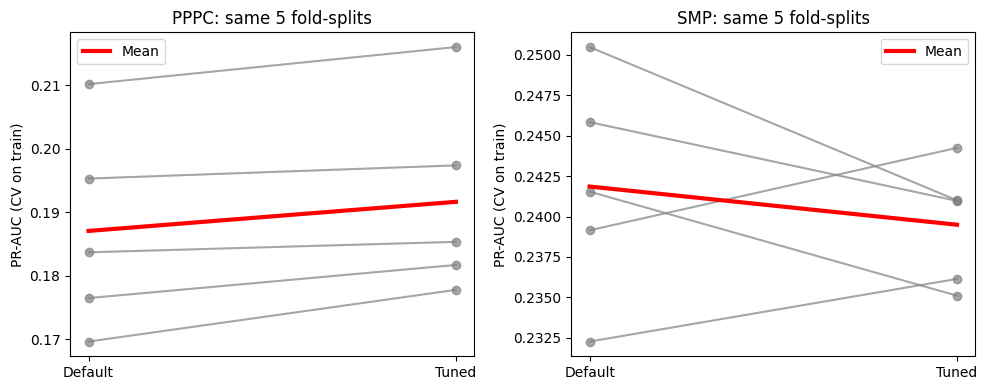

In [19]:
# Part 8 - Step 2: Confirmation check of tuned dials (new fold-splits, TRAIN set only)

# 1) Which labels did the rule select for tuning?
to_check = [lab for lab, info in tuned_info.items() if info["adopt"]]
print("Labels to confirm:", to_check)

# 2) For each of them: tuned vs default on the SAME 5 fold-splits (seeds 100 to 104)
rows = []
for lab in to_check:
    fname, mname = tuned_info[lab]["feat"], tuned_info[lab]["model"]
    params = tuned_info[lab]["params"]
    ytr = Y_tr[lab].values
    Xtr = FEATS[fname][0]
    for rep in range(N_REPEATS):
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + rep)
        model = get_models()[mname].set_params(**params)       # model with tuned dials
        score = cross_val_predict(model, Xtr, ytr, cv=cv_r,
                                  method="decision_function", n_jobs=-1)
        pr_tuned = average_precision_score(ytr, score)
        # default result of the same repeat, saved in Part 7
        pr_default = rep_df[(rep_df["label"] == lab) & (rep_df["feat"] == fname) &
                            (rep_df["model"] == mname) & (rep_df["rep"] == rep)]["PR"].iloc[0]
        rows.append({"label": lab, "rep": rep, "default": pr_default, "tuned": pr_tuned})

conf = pd.DataFrame(rows)
conf["tuned_better"] = conf["tuned"] > conf["default"]

# 3) Summary and decision (rule fixed in advance)
summary_rows = []
for lab in to_check:
    d = conf[conf["label"] == lab]
    mean_d, mean_t = d["default"].mean(), d["tuned"].mean()
    wins = int(d["tuned_better"].sum())
    confirmed = bool(mean_t > mean_d and wins >= 4)
    tuned_info[lab]["confirmed"] = confirmed
    summary_rows.append({
        "label": lab,
        "default (mean ± SD)": f"{mean_d:.3f} ± {d['default'].std():.3f}",
        "tuned (mean ± SD)": f"{mean_t:.3f} ± {d['tuned'].std():.3f}",
        "tuned better in": f"{wins} of {len(d)} repeats",
        "confirmed": confirmed,
    })
print("\n===== Confirmation check (new fold-splits) =====")
print(pd.DataFrame(summary_rows).to_string(index=False))

# 4) Final dials for every label: tuned if confirmed, otherwise default (empty dict = default)
final_spec = {}
for lab, (fname, mname) in final_choice.items():
    use_tuned = tuned_info[lab].get("confirmed", False)
    final_spec[lab] = {"feat": fname, "model": mname,
                       "params": tuned_info[lab]["params"] if use_tuned else {}}
print("\n===== Final specification of the 4 models =====")
for lab, s in final_spec.items():
    kind = "tuned" if s["params"] else "default"
    print(f"{lab}: {s['feat']} + {s['model']} | {kind} | dials = {s['params'] if s['params'] else 'sklearn defaults'}")

# 5) Graph: tuned vs default in every repeat (a line joins the same repeat)
fig, axes = plt.subplots(1, len(to_check), figsize=(5 * len(to_check), 4))
axes = np.atleast_1d(axes)
for ax, lab in zip(axes, to_check):
    d = conf[conf["label"] == lab]
    for _, r in d.iterrows():
        ax.plot([0, 1], [r["default"], r["tuned"]], color="gray", marker="o", alpha=0.7)
    ax.plot([0, 1], [d["default"].mean(), d["tuned"].mean()], color="red", linewidth=3, label="Mean")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Default", "Tuned"])
    ax.set_ylabel("PR-AUC (CV on train)")
    ax.set_title(f"{lab}: same 5 fold-splits")
    ax.legend()
plt.tight_layout()
plt.savefig("tuning_confirmation.png", dpi=150)
plt.show()

### Part 8 conclusion
- Only the 4 final models were tuned (RandomizedSearchCV, train set only). A tuned setting was kept only if it beat the default by more than the default's repeated-CV SD, and then had to win in at least 4 of 5 new fold-splits.
- HBD and MND: no gain from tuning, defaults kept.
- SMP: an apparent gain (+0.020) disappeared on new fold-splits (tuned 0.239 vs default 0.242), so defaults were kept. This is an example of optimism from picking the best of many random tries.
- PPPC: tuned SVM was better in 5 of 5 repeats but by only +0.005 PR-AUC (well inside the default SD of 0.016), so tuned and default models are practically equivalent.

## Part 9: Final Evaluation on the Test Set
The 4 final models are trained on the full train set and evaluated ONCE on the held-out test set.
Nothing is changed after seeing these results.

===== Test set: ranking metrics (final models, unweighted scores) =====
label       model  test positives  prevalence  PR_test         95% CI  Skill  ROC_test  PR_CV_train
  HBD Torsion+SVM             146       0.510    0.676 [0.592, 0.762]  0.338     0.689        0.752
  MND Torsion+ADA             203       0.710    0.741 [0.677, 0.817]  0.107     0.572        0.767
 PPPC  Hybrid+SVM              25       0.087    0.134 [0.076, 0.264]  0.051     0.572        0.187
  SMP Torsion+SVM              42       0.147    0.253 [0.151, 0.389]  0.125     0.577        0.242

===== Test set: threshold metrics (score > 0 = predict Yes) =====
label    setting  Accuracy  Precision  Recall   MCC  Predicted Yes  Silly baseline acc
  HBD unweighted     0.626      0.626   0.664 0.251            155               0.510
  HBD   weighted     0.626      0.629   0.651 0.251            151               0.510
  MND unweighted     0.713      0.714   0.995 0.085            283               0.710
  MND   weigh

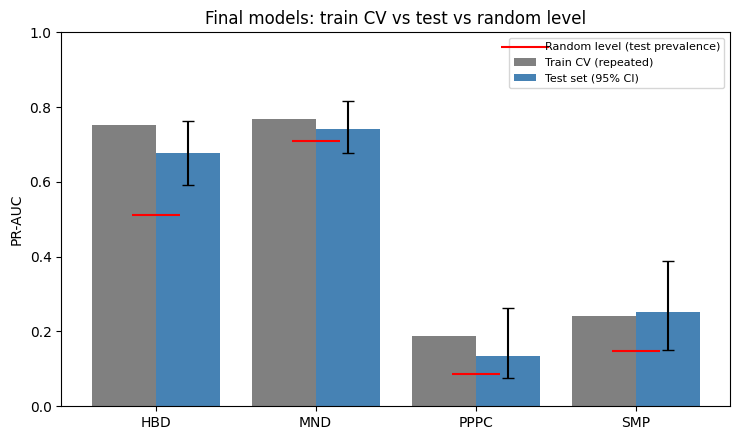

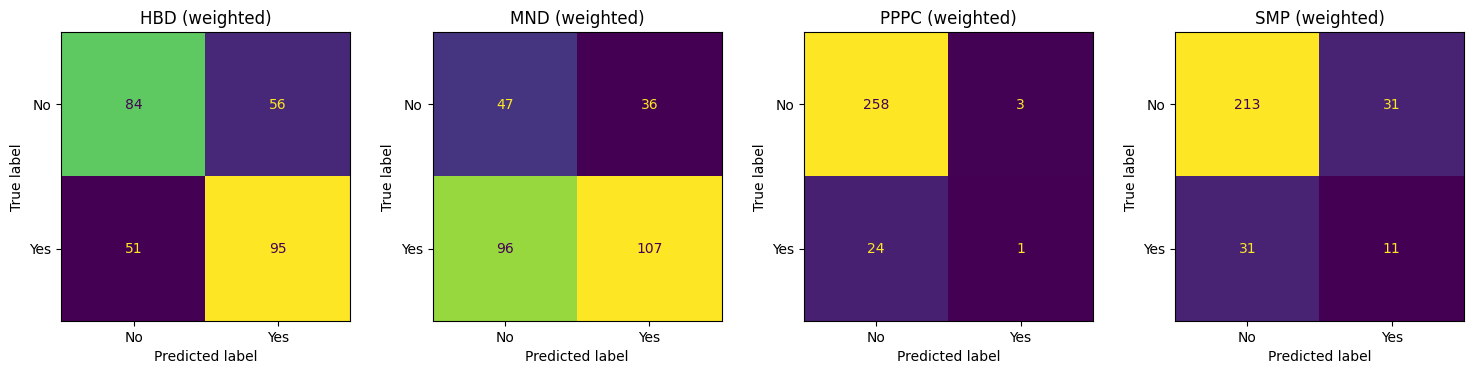

In [20]:
# Part 9 - Step 1: Evaluate the 4 final models ONCE on the test set
prev_te = Y_te.mean()
test_store = {}
rows_rank, rows_thr = [], []

for lab, spec in final_spec.items():
    fname, mname, params = spec["feat"], spec["model"], spec["params"]
    Xtr, Xte = FEATS[fname]
    ytr, yte = Y_tr[lab].values, Y_te[lab].values
    sw = compute_sample_weight("balanced", ytr)

    # 1) Fit on the full train set: without weights and with weights
    for setting in ["unweighted", "weighted"]:
        model = get_models()[mname].set_params(**params)
        if setting == "weighted":
            model.fit(Xtr, ytr, sample_weight=sw)
        else:
            model.fit(Xtr, ytr)
        score = model.decision_function(Xte)
        pred = (score > 0).astype(int)
        test_store[(lab, setting)] = (yte, score, pred)

        rows_thr.append({
            "label": lab, "setting": setting,
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred, zero_division=0),
            "MCC": matthews_corrcoef(yte, pred),
            "Predicted Yes": int(pred.sum()),
            "Silly baseline acc": max(prev_te[lab], 1 - prev_te[lab]),
        })

    # 2) Ranking metrics (main result = unweighted scores)
    yte_, s_, _ = test_store[(lab, "unweighted")]
    pr = average_precision_score(yte_, s_)
    lo, hi = boot_pr_ci(yte_, s_)
    cv_mean = summ[(summ["label"] == lab) & (summ["feat"] == fname) &
                   (summ["model"] == mname)]["mean"].iloc[0]
    rows_rank.append({
        "label": lab, "model": f"{fname}+{mname}",
        "test positives": int(yte_.sum()),
        "prevalence": prev_te[lab],
        "PR_test": pr, "CI_low": lo, "CI_high": hi,
        "Skill": (pr - prev_te[lab]) / (1 - prev_te[lab]),
        "ROC_test": roc_auc_score(yte_, s_),
        "PR_CV_train": cv_mean,
    })

rank_df = pd.DataFrame(rows_rank)
thr_df = pd.DataFrame(rows_thr)
rank_df.to_csv("test_ranking_metrics.csv", index=False)
thr_df.to_csv("test_threshold_metrics.csv", index=False)

show = rank_df.copy()
show["95% CI"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(rank_df["CI_low"], rank_df["CI_high"])]
show = show[["label", "model", "test positives", "prevalence", "PR_test", "95% CI",
             "Skill", "ROC_test", "PR_CV_train"]].round(3)
print("===== Test set: ranking metrics (final models, unweighted scores) =====")
print(show.to_string(index=False))
print("\n===== Test set: threshold metrics (score > 0 = predict Yes) =====")
print(thr_df.round(3).to_string(index=False))

# 3) Graph 1: PR-AUC on test (with CI) vs train CV vs random level
fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(len(rank_df))
ax.bar(x - 0.2, rank_df["PR_CV_train"], width=0.4, color="gray", label="Train CV (repeated)")
ax.bar(x + 0.2, rank_df["PR_test"], width=0.4, color="steelblue", label="Test set (95% CI)",
       yerr=[rank_df["PR_test"] - rank_df["CI_low"], rank_df["CI_high"] - rank_df["PR_test"]],
       capsize=4)
ax.scatter(x, rank_df["prevalence"], color="red", marker="_", s=1200, zorder=3,
           label="Random level (test prevalence)")
ax.set_xticks(x)
ax.set_xticklabels(rank_df["label"])
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 1)
ax.set_title("Final models: train CV vs test vs random level")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("test_pr_vs_cv_vs_random.png", dpi=150)
plt.show()

# 4) Graph 2: confusion matrices on the test set (weighted models)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, lab in zip(axes, labels.keys()):
    yte_, _, pred_ = test_store[(lab, "weighted")]
    ConfusionMatrixDisplay(confusion_matrix(yte_, pred_),
                           display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{lab} (weighted)")
plt.tight_layout()
plt.savefig("test_confusion_matrices.png", dpi=150)
plt.show()

split 0 done | time so far: 17 sec
split 1 done | time so far: 33 sec
split 2 done | time so far: 50 sec
split 3 done | time so far: 68 sec
split 4 done | time so far: 85 sec
split 5 done | time so far: 102 sec
split 6 done | time so far: 120 sec
split 7 done | time so far: 136 sec
split 8 done | time so far: 152 sec
split 9 done | time so far: 168 sec

===== Final models on 10 random splits (mean ± SD) =====
                  PR          Skill            ROC MCC_unweighted   MCC_weighted Recall_weighted  Skill min  Skill max splits with Skill > 0
label                                                                                                                                       
HBD    0.744 ± 0.037  0.470 ± 0.065  0.747 ± 0.026  0.377 ± 0.047  0.381 ± 0.065   0.707 ± 0.029      0.380      0.603              10 of 10
MND    0.773 ± 0.022  0.236 ± 0.061  0.620 ± 0.020  0.015 ± 0.051  0.199 ± 0.038   0.578 ± 0.034      0.089      0.286              10 of 10
PPPC   0.196 ± 0.042  0

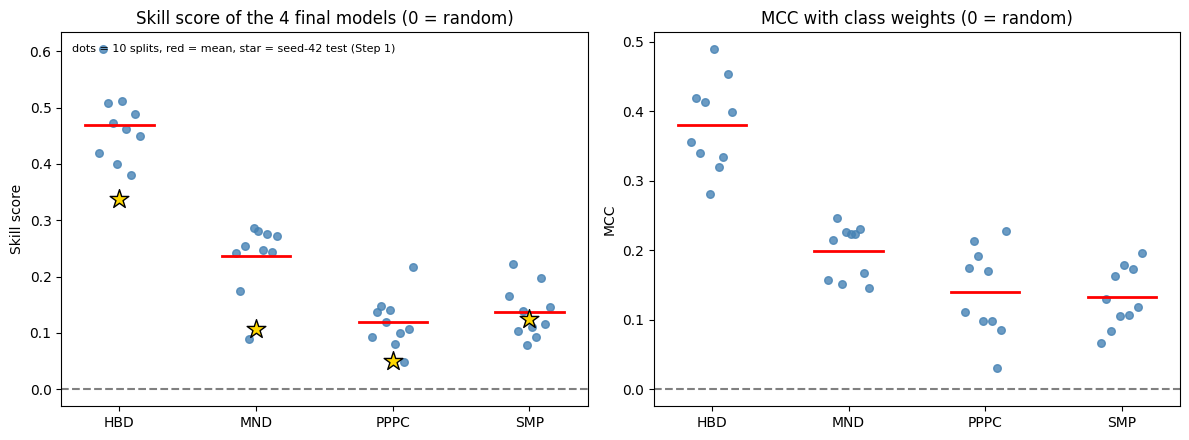

In [21]:
# Part 9 - Step 2: Same 4 final models on 10 random 80/20 splits
# 1) Helper: build train/test feature tables for ONE split
def get_features(fname, tr, te):
    if fname in ["Descriptors", "Hybrid"]:
        sc = StandardScaler().fit(desc_log.iloc[tr])        # scaling learned from this split's TRAIN only
        D_tr_s = sc.transform(desc_log.iloc[tr])
        D_te_s = sc.transform(desc_log.iloc[te])
        if fname == "Descriptors":
            return D_tr_s, D_te_s
        return (np.hstack([FP["Morgan"][tr], D_tr_s]),
                np.hstack([FP["Morgan"][te], D_te_s]))
    return FP[fname][tr], FP[fname][te]                       # plain fingerprints

# 2) Loop: 10 splits x 4 final models
rows = []
t0 = time.time()
for sd in range(10):
    tr, te = train_test_split(np.arange(len(df)), test_size=0.20,
                              random_state=sd, stratify=strat_key)
    for lab, spec in final_spec.items():
        Xtr_s, Xte_s = get_features(spec["feat"], tr, te)
        ytr_s, yte_s = Y[lab].values[tr], Y[lab].values[te]
        prev = yte_s.mean()
        sw = compute_sample_weight("balanced", ytr_s)

        row = {"seed": sd, "label": lab}
        for setting in ["unweighted", "weighted"]:
            model = get_models()[spec["model"]].set_params(**spec["params"])
            if setting == "weighted":
                model.fit(Xtr_s, ytr_s, sample_weight=sw)
            else:
                model.fit(Xtr_s, ytr_s)
            score = model.decision_function(Xte_s)
            pred = (score > 0).astype(int)

            if setting == "unweighted":
                pr = average_precision_score(yte_s, score)
                row["PR"] = pr
                row["Skill"] = (pr - prev) / (1 - prev)
                row["ROC"] = roc_auc_score(yte_s, score)
                row["MCC_unweighted"] = matthews_corrcoef(yte_s, pred)
            else:
                row["MCC_weighted"] = matthews_corrcoef(yte_s, pred)
                row["Recall_weighted"] = recall_score(yte_s, pred, zero_division=0)
        rows.append(row)
    print(f"split {sd} done | time so far: {time.time() - t0:.0f} sec")

split_df = pd.DataFrame(rows)
split_df.to_csv("repeated_splits_final_models.csv", index=False)

# 3) Summary: mean +/- SD, and in how many splits the model beat random
def ms(x):
    return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}"

cols = ["PR", "Skill", "ROC", "MCC_unweighted", "MCC_weighted", "Recall_weighted"]
table = split_df.groupby("label")[cols].agg(ms).loc[list(labels.keys())]
table["Skill min"] = split_df.groupby("label")["Skill"].min().round(3)
table["Skill max"] = split_df.groupby("label")["Skill"].max().round(3)
table["splits with Skill > 0"] = split_df.groupby("label")["Skill"].apply(lambda s: f"{int((s > 0).sum())} of 10")
print("\n===== Final models on 10 random splits (mean ± SD) =====")
print(table.to_string())

# 4) Graph: skill score and weighted MCC of every split (dots)
step1_skill = rank_df.set_index("label")["Skill"]          # seed-42 test result from Step 1
jitter = np.linspace(-0.15, 0.15, 10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for j, lab in enumerate(labels.keys()):
    d = split_df[split_df["label"] == lab].sort_values("seed")
    axes[0].scatter(j + jitter, d["Skill"], color="steelblue", s=30, alpha=0.8)
    axes[0].plot([j - 0.25, j + 0.25], [d["Skill"].mean()] * 2, color="red", linewidth=2)
    axes[0].scatter(j, step1_skill[lab], color="gold", edgecolor="black", marker="*", s=200, zorder=5)
    axes[1].scatter(j + jitter, d["MCC_weighted"], color="steelblue", s=30, alpha=0.8)
    axes[1].plot([j - 0.25, j + 0.25], [d["MCC_weighted"].mean()] * 2, color="red", linewidth=2)
for ax, title, yl in [(axes[0], "Skill score of the 4 final models (0 = random)", "Skill score"),
                      (axes[1], "MCC with class weights (0 = random)", "MCC")]:
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(list(labels.keys()))
    ax.set_ylabel(yl)
    ax.set_title(title)
axes[0].text(0.02, 0.97, "dots = 10 splits, red = mean, star = seed-42 test (Step 1)",
             transform=axes[0].transAxes, va="top", fontsize=8)
plt.tight_layout()
plt.savefig("repeated_splits_final_models.png", dpi=150)
plt.show()

### Part 9 conclusion
- The 4 final models were evaluated once on the held-out test set (seed 42): PR-AUC HBD 0.676, MND 0.741, PPPC 0.134, SMP 0.253. Only HBD is clearly above random (CI lower bound 0.592 vs prevalence 0.510); MND and PPPC are not distinguishable from random on this test set, and SMP is only marginally above (0.151 vs 0.147).
- The seed-42 test set turned out to be harder than average: on 10 other random splits the mean skill was HBD 0.47, MND 0.24, SMP 0.14, PPPC 0.12 (all splits above 0). These 10-split values are somewhat optimistic because the model choice was made on the seed-42 train set; the seed-42 test result is the clean estimate.
- Class weighting helped SMP and MND (MCC 0.05 to 0.13 and 0.02 to 0.20) but made no difference for the tuned PPPC SVM.
- Overall: HBD is moderately predictable from structure, MND weakly, PPPC and SMP only slightly.

## Part 10: Final Summary and Limitations
All results in one table and one figure, followed by limitations.

===== FINAL SUMMARY =====
                                                              HBD                               MND                              PPPC                                  SMP
final model                                           Torsion+SVM                       Torsion+ADA                Hybrid+SVM (tuned)                          Torsion+SVM
prevalence (all drugs)                                      0.521                             0.698                             0.088                                0.149
CV PR (train, repeated)                                     0.752                             0.767                             0.187                                0.242
Test PR (seed 42)                                           0.676                             0.741                             0.134                                0.253
Test 95% CI                                        [0.592, 0.762]                    [0.677, 0.817]                    

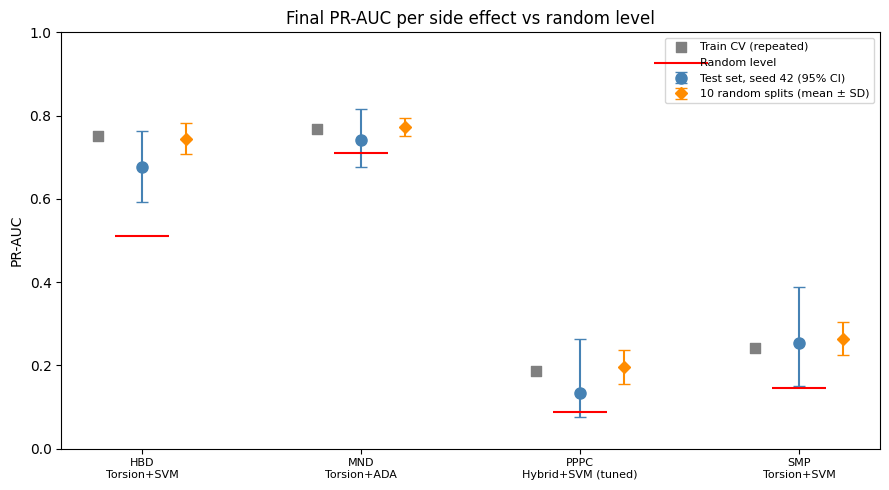

In [22]:
# Part 10 - Step 1: Final summary table and final figure
idx = list(labels.keys())
r = rank_df.set_index("label").loc[idx]            # seed-42 test results (Part 9, Step 1)

# 1) Mean and SD over the 10 random splits (Part 9, Step 2)
sp = split_df.groupby("label").agg(
    PR_mean=("PR", "mean"), PR_sd=("PR", "std"),
    Skill_mean=("Skill", "mean"), Skill_sd=("Skill", "std"),
    MCCw_mean=("MCC_weighted", "mean"), MCCw_sd=("MCC_weighted", "std"),
).loc[idx]

# 2) Final table
final_table = pd.DataFrame({
    "final model": [f"{final_spec[l]['feat']}+{final_spec[l]['model']}"
                    + (" (tuned)" if final_spec[l]["params"] else "") for l in idx],
    "prevalence (all drugs)": Y.mean().loc[idx].round(3).values,
    "CV PR (train, repeated)": r["PR_CV_train"].round(3).values,
    "Test PR (seed 42)": r["PR_test"].round(3).values,
    "Test 95% CI": [f"[{a:.3f}, {b:.3f}]" for a, b in zip(r["CI_low"], r["CI_high"])],
    "Test skill (seed 42)": r["Skill"].round(3).values,
    "Skill, 10 splits (mean ± SD)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(sp["Skill_mean"], sp["Skill_sd"])],
    "MCC weighted, 10 splits": [f"{m:.3f} ± {s:.3f}" for m, s in zip(sp["MCCw_mean"], sp["MCCw_sd"])],
    "margin (CI low - random)": (r["CI_low"] - r["prevalence"]).round(3).values,
    "verdict": np.where(r["CI_low"] > r["prevalence"],
                        "above random on test (check margin)",
                        "not clearly above random on test"),
}, index=idx)

final_table.to_csv("final_summary_table.csv")
print("===== FINAL SUMMARY =====")
print(final_table.T.to_string())

# 3) Final figure: PR-AUC of every label from 4 angles
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(idx))
ax.scatter(x - 0.2, r["PR_CV_train"], marker="s", color="gray", s=60, label="Train CV (repeated)")
ax.errorbar(x, r["PR_test"],
            yerr=[r["PR_test"] - r["CI_low"], r["CI_high"] - r["PR_test"]],
            fmt="o", color="steelblue", capsize=4, markersize=8, label="Test set, seed 42 (95% CI)")
ax.errorbar(x + 0.2, sp["PR_mean"], yerr=sp["PR_sd"],
            fmt="D", color="darkorange", capsize=4, label="10 random splits (mean ± SD)")
ax.scatter(x, r["prevalence"], marker="_", color="red", s=1500, zorder=3, label="Random level")
ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{final_table.loc[l, 'final model']}" for l in idx], fontsize=8)
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 1)
ax.set_title("Final PR-AUC per side effect vs random level")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig("final_pr_vs_random.png", dpi=150)
plt.show()

### Limitations

**Data**
- SIDER labels record whether a side-effect category was reported for a drug. They carry no dose, timing, patient or mechanism information, and a report is not proof of causation.
- Molecules were not standardised (no desalting, charge neutralisation or largest-fragment selection). The data contain ions, salts and very large molecules (MolWt from 6.9 to 7595, valence electrons from 0 to 2702).
- 31 drugs have an empty AtomPair fingerprint and 60 have an empty Torsion fingerprint (very small molecules). In large molecules, AtomPair and Pattern bits saturate, so different features share the same bit (hash collisions).

**Small number of positives**
- PPPC has only 125 positive drugs (25 in the test set) and SMP has 213 (42 in the test set). Test confidence intervals are wide, and single-split numbers for these two labels are unreliable.

**Validation**
- The train/test split is random, not scaffold-based. Similar molecules can sit in both sets, so performance on truly new chemistry is likely lower.
- The seed-42 test set was harder than average. The 10-random-split

In [23]:
# Part 10 - Step 2: List the files created by the notebook
import os

files = sorted(f for f in os.listdir(".")
               if f.endswith((".csv", ".png")) and not f.startswith("."))
sizes = [round(os.path.getsize(f) / 1024, 1) for f in files]
file_table = pd.DataFrame({"file": files, "size_KB": sizes})
print("Files to upload to GitHub together with the notebook:")
print(file_table.to_string(index=False))
print("\nNumber of files:", len(files))

Files to upload to GitHub together with the notebook:
                            file  size_KB
            class_prevalence.png     35.8
         cv_baseline_results.csv      6.6
         cv_skill_by_feature.png     29.3
            cv_skill_heatmap.png    122.9
           cv_top5_per_label.csv      1.9
           cv_top5_per_label.png     98.9
         cv_weighted_results.csv      8.7
     descriptors_raw_vs_log2.png     69.2
         descriptors_scatter.png     46.0
         example_metrics_hbd.png     63.6
          final_pr_vs_random.png     50.9
         final_summary_table.csv      0.7
         fingerprint_bits_on.png     63.1
           logit_example_hbd.png     52.9
           logit_forest_plot.png     68.0
           logit_odds_ratios.csv      2.0
  paired_comparison_train_cv.csv      0.6
  paired_comparison_train_cv.png     70.7
         repeated_cv_summary.csv      1.4
            repeated_cv_top3.csv      2.2
            repeated_cv_top3.png     89.9
repeated_splits_final_